# Benchmark

**This notebook is your deliverable, and it is what gets graded.** You have three
tables of evaluation runs, plus harness trajectories. Fifteen questions follow,
grouped into five sections. Answer them here, in this file.

**Time expectation: 60 minutes.** You are not expected to finish every question
perfectly. A well-reasoned partial answer with its evidence shown is worth more
than a confident number with no working.

## A note on vocabulary

Two fields in this data are easy to conflate, and several questions turn on the
difference:

- **Harness** (`harness_name`) — how the agent is organised: Direct Tool,
  Planner Executor, Memory ReAct, Specialist Orchestrator.
- **Runner** (`runner_version`) — the version of the software that executed the
  run.

They vary independently, and two runs can share one while differing in the other.

## How to answer

Each question has a **work area** (code cells, add as many as you like) and an
**answer cell** (markdown). Write your response in the answer cell, explain how
you arrived at it, and cite the evidence behind it — either from the released
data or from output you produced in the work area.

Your work area is read too, as evidence for the answer above it. A derivation
that produces the figure you quote supports it; a bare assertion with nothing
behind it does not.


---

## Setup

In [38]:
import pandas as pd
import numpy as np

# low_memory=False keeps pandas from guessing dtypes chunk by chunk on the sparse
# text columns; without it the load emits a DtypeWarning.
runs = pd.read_csv("runs.csv", low_memory=False)
tasks = pd.read_csv("tasks.csv", low_memory=False)
calls = pd.read_csv("model_calls.csv", low_memory=False)

print(f"runs   {runs.shape}")
print(f"tasks  {tasks.shape}")
print(f"calls  {calls.shape}")

# Trajectories:
#   python3 get_trajectory <run_id> <task_id>     one trace, printed as JSON
#   python3 get_trajectory --list-runs            runs that have trajectories
#   trajectories/selected/                  ten traces, readable directly
#   trajectories/trajectory_index.csv      maps run and task to a record
runs.head()


runs   (54, 16)
tasks  (2550, 14)
calls  (67529, 11)


,run_id,benchmark_id,model_name,harness_name,repeat_group_id,runner_version,price_catalog_version,run_status,token_budget_per_task,tasks_expected,tasks_executed,tasks_passed,total_cost_usd,prompt_tokens,completion_tokens,cached_tokens
0,run_0000,artifact_hard,Aster Small,direct_tool,NaN,2026.01.3,2026.01,partial,8000,45,33,8,0.054967,196103.0,4755.0,0.0
1,run_0001,artifact_hard,AsterSmall,PlannerExecutor,grp_7f5f44c0,2026.02.1,2026.01,finished,16000,45,45,19,0.127896,422364.0,16298.0,64192.0
2,run_0002,artifact_hard,Aster Small,PlannerExecutor,grp_7f5f44c0,2026.02.1,2026.01,finished,16000,45,45,15,0.130792,418290.0,19311.0,69539.0
3,run_0003,artifact_hard,AsterSmall,planner_executor,grp_7f5f44c0,2026.02.1,2026.01,finished,16000,45,45,20,0.116386,368792.0,17739.0,66668.0
4,run_0004,artifact_hard,aster-large-20260114,Direct Tool,NaN,2026.01.4,2026.01,finished,16000,45,45,21,0.177806,391209.0,10665.0,0.0


### Cleaning: canonical model/harness names and run-quality flags

Every later question depends on this cell. It (1) maps the 12 model and 9 harness spellings onto 6 models / 4 harnesses, (2) adds `score = tasks_passed / tasks_expected`, and (3) flags runs whose numbers should not be trusted at face value, with each flag computed from the data. `runs_ok` is the 49 unflagged runs; `tasks` and `calls` gain the canonical labels via merge.


In [39]:
# --- Data cleaning: canonical names + run-quality flags ---------------------
# Almost every later question groups by model or harness, but runs.csv spells
# the 6 models 12 different ways (e.g. "Aster Large" / "aster-large-20260114")
# and the 4 harnesses 9 ways ("direct_tool" / "Direct Tool" / "direct-tool").
# Normalise each string: lowercase, strip a trailing -YYYYMMDD date stamp, drop
# spaces/underscores/hyphens, then map the result onto one canonical label.
import re

def _key(s):
    s = re.sub(r"-?\d{8}$", "", str(s).lower())   # drop date-stamped suffix
    return re.sub(r"[^a-z]", "", s)               # drop separators / case

MODEL_CANON = {
    "astersmall": "Aster Small", "asterlarge": "Aster Large",
    "micabase":   "Mica Base",   "micapro":    "Mica Pro",
    "noribase":   "Nori Base",   "noripro":    "Nori Pro",
}
HARNESS_CANON = {
    "directtool":      "Direct Tool",      "plannerexecutor":        "Planner Executor",
    "memoryreact":     "Memory ReAct",     "specialistorchestrator": "Specialist Orchestrator",
}

runs["model"]   = runs["model_name"].map(lambda s: MODEL_CANON[_key(s)])
runs["harness"] = runs["harness_name"].map(lambda s: HARNESS_CANON[_key(s)])
runs["family"]  = runs["model"].str.split().str[0]          # Aster / Mica / Nori
runs["size"]    = runs["model"].str.split().str[1]          # Small/Large, Base/Pro

# Score = tasks passed / tasks expected (fraction). See Q1 for the reasoning.
runs["score"] = runs["tasks_passed"] / runs["tasks_expected"]

# --- Run-quality flags, each derived from the data rather than hard-coded ---
# Fraction of a run's tasks that died with a JSON-parse error before the model
# could do anything ("Expecting value: line 1 column 1").
_json_err_frac = (tasks["error"].str.startswith("Expecting value", na=False)
                  .groupby(tasks["run_id"]).mean())
# Cost per token relative to the same model's median: a run priced at <10% of
# its siblings has a pricing defect, not a cheap model.
_tok = runs["prompt_tokens"] + runs["completion_tokens"]
runs["cost_per_mtok"] = runs["total_cost_usd"] / _tok * 1e6
_model_median = runs.groupby("model")["cost_per_mtok"].transform("median")

runs["flag_partial"]      = runs["run_status"] != "finished"               # run_0000: 33/45 tasks executed
runs["flag_no_calls"]     = ~runs["run_id"].isin(calls["run_id"])          # run_0025: no calls/cost/tokens/runner
runs["flag_all_json_err"] = runs["run_id"].map(_json_err_frac).fillna(0).eq(1.0)  # run_0036: 50/50 tasks JSON error
runs["flag_no_price_cat"] = runs["price_catalog_version"].isna()           # run_0008, run_0023, run_0025
runs["flag_cost_outlier"] = runs["cost_per_mtok"] < 0.10 * _model_median   # run_0008, run_0023: ~1000x too cheap

FLAG_COLS = [c for c in runs.columns if c.startswith("flag_")]
runs["n_flags"] = runs[FLAG_COLS].sum(axis=1)
runs["clean"]   = runs["n_flags"] == 0

# Push canonical labels down to the task and call tables so any group-by works.
_lab = runs[["run_id", "benchmark_id", "model", "harness", "family", "size",
             "token_budget_per_task", "repeat_group_id", "clean"]]
tasks = tasks.merge(_lab, on="run_id", how="left")
calls = calls.merge(_lab.drop(columns="benchmark_id"), on="run_id", how="left")

# Convenience view used by most performance/cost questions.
runs_ok = runs[runs["clean"]].copy()

# ---- Report what was done -------------------------------------------------
print("Model spellings  -> canonical:")
print(runs.groupby("model")["model_name"].unique().to_string())
print("\nHarness spellings -> canonical:")
print(runs.groupby("harness")["harness_name"].unique().to_string())
print(f"\nCanonical counts: {runs['model'].nunique()} models, {runs['harness'].nunique()} harnesses")
print(f"\nFlagged runs ({(~runs['clean']).sum()} of {len(runs)}); runs_ok has {len(runs_ok)} rows:")
_f = runs.loc[~runs["clean"], ["run_id", "benchmark_id", "model", "harness",
                                "tasks_executed", "tasks_passed", "total_cost_usd",
                                "cost_per_mtok"] + FLAG_COLS]
print(_f.to_string(index=False))


Model spellings  -> canonical:
model
Aster Large        [aster-large-20260114, Aster Large]
Aster Small                  [Aster Small, AsterSmall]
Mica Base                       [mica-base, Mica Base]
Mica Pro       [Mica-Pro, Mica Pro, mica-pro-20260202]
Nori Base              [Nori Base, nori-base-20260119]
Nori Pro                                    [Nori Pro]

Harness spellings -> canonical:
harness
Direct Tool                          [direct_tool, Direct Tool, direct-tool]
Memory ReAct                                    [memory_react, Memory ReAct]
Planner Executor           [PlannerExecutor, planner_executor, Planner Ex...
Specialist Orchestrator                            [specialist_orchestrator]

Canonical counts: 6 models, 4 harnesses

Flagged runs (5 of 54); runs_ok has 49 rows:
  run_id  benchmark_id       model                 harness  tasks_executed  tasks_passed  total_cost_usd  cost_per_mtok  flag_partial  flag_no_calls  flag_all_json_err  flag_no_price_cat  flag_cost

---

# Section 1: Data interpretation


### Q1. How do you calculate the score reported? Do it on `run_0000`.

**Work**


In [40]:
# Q1: derive the score for run_0000 from the task grid, not from the stored counts.
from math import sqrt

def wilson_ci(k, n, z=1.96):
    # Wilson score interval for a binomial proportion; reused in later questions.
    p = k / n
    centre = (p + z*z/(2*n)) / (1 + z*z/n)
    half   = z * sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return centre - half, centre + half

r0 = tasks[tasks["run_id"] == "run_0000"]

n_expected = len(r0)                                    # rows in the benchmark's task grid
n_executed = (r0["task_status"] == "completed").sum()   # rows with a recorded outcome
n_passed   = int(r0["passed"].sum())                    # passed is empty on not_executed rows
print(f"run_0000 from tasks.csv: expected={n_expected}  executed={n_executed}  passed={n_passed}")

# Cross-check against the stored run-level counts
stored = runs.set_index("run_id").loc["run_0000", ["tasks_expected", "tasks_executed", "tasks_passed", "run_status"]]
print("run_0000 from runs.csv :", stored.to_dict())
assert (n_expected, n_executed, n_passed) == tuple(stored[:3]), "task grid disagrees with runs.csv"

# The two candidate denominators
score_expected = n_passed / n_expected
score_executed = n_passed / n_executed
print(f"\nscore = passed / expected = {n_passed}/{n_expected} = {score_expected:.4f}  <- reported score")
print(f"pass rate on executed only = {n_passed}/{n_executed} = {score_executed:.4f}  (conditional on the task running)")

# What was skipped, and was the model passing tasks like them?
print("\nnot-executed tasks by difficulty:")
print(r0[r0["task_status"] == "not_executed"]["difficulty_band"].value_counts().to_string())
print("\npass rate on executed tasks by difficulty:")
print(r0[r0["task_status"] == "completed"].groupby("difficulty_band")["passed"]
        .agg(passed="sum", n="size", rate="mean").round(3).to_string())

# How precise is a single 45-task score?
lo, hi = wilson_ci(n_passed, n_expected)
print(f"\n95% Wilson CI for {n_passed}/{n_expected}: [{lo:.3f}, {hi:.3f}]  (about +/-{(hi-lo)/2*100:.0f} points)")


run_0000 from tasks.csv: expected=45  executed=33  passed=8
run_0000 from runs.csv : {'tasks_expected': 45, 'tasks_executed': 33, 'tasks_passed': 8, 'run_status': 'partial'}

score = passed / expected = 8/45 = 0.1778  <- reported score
pass rate on executed only = 8/33 = 0.2424  (conditional on the task running)

not-executed tasks by difficulty:
difficulty_band
medium    6
hard      4
easy      2

pass rate on executed tasks by difficulty:
                passed   n      rate
difficulty_band                     
easy                 6  13  0.461538
hard                 1  11  0.090909
medium               1   9  0.111111

95% Wilson CI for 8/45: [0.093, 0.313]  (about +/-11 points)


**Answer to Q1**

**Score = tasks_passed / tasks_expected. run_0000: 8 / 45 = 0.178 (17.8%).**

**What I calculated.** From `tasks.csv`, run_0000 has 45 rows (the benchmark's task set), 33 with
`task_status = completed`, 12 `not_executed` with `passed` empty, and `sum(passed) = 8`. These match
`tasks_expected / tasks_executed / tasks_passed` in `runs.csv`. The data dictionary says no score is stored,
"a rate is derived", so the score is passed over a denominator.

**Why 45 and not 33.** The benchmark defines the task set; a task with no outcome is a task not passed. Dividing
by executed (8/33 = 24.2%) would reward a run for crashing on tasks, and here it would overstate: the 12 skipped
tasks are 6 medium / 4 hard / 2 easy, and this model passed only ~10% of executed medium and hard tasks. Every
other artifact_hard run is out of 45, so 8/45 is the only comparable figure. `run_status = partial` is the data's
own flag; the run is excluded from later comparisons.

**Precision.** 95% Wilson interval for 8/45 is [9%, 31%], about +/-11 points for a single run.


### Q2. Which setups were run more than once, and what qualifies two runs as repeats?

**Work**


In [41]:
# Q2: does the repeat_group_id label agree with what the setup columns say?
pd.set_option("display.width", 200)
SETUP = ["benchmark_id", "model", "harness", "token_budget_per_task"]   # canonical names from the cleaning cell
show  = ["run_id", "repeat_group_id", "model_name", "harness_name"] + SETUP[1:] + ["runner_version", "tasks_passed", "clean"]

labelled = runs[runs["repeat_group_id"].notna()].sort_values(["repeat_group_id", "run_id"])
print(f"{len(labelled)} runs carry a repeat_group_id, in {labelled['repeat_group_id'].nunique()} groups\n")
print(labelled[show].to_string(index=False))

# Label -> columns: within each group, how many distinct values does each setup field take?
print("\nDistinct values per field within each labelled group (1 = constant):")
print(labelled.groupby("repeat_group_id")[SETUP + ["runner_version", "price_catalog_version"]].nunique(dropna=False).to_string())
print("\nlabelled runs with a null runner_version or price_catalog_version:")
print(labelled[labelled[["runner_version", "price_catalog_version"]].isna().any(axis=1)][["run_id", "repeat_group_id", "runner_version", "price_catalog_version", "clean"]].to_string(index=False))

# Columns -> label: find repeated setups from the columns alone and compare to the label.
by_cols = runs.groupby(SETUP)["run_id"].apply(set)
by_cols = by_cols[by_cols.str.len() > 1]
by_label = labelled.groupby("repeat_group_id")["run_id"].apply(set)
print(f"\nrepeated setups from columns: {len(by_cols)} setups / {by_cols.str.len().sum()} runs")
print(f"repeat groups from label    : {len(by_label)} groups / {by_label.str.len().sum()} runs")
print("identical partition of runs :", set(map(frozenset, by_cols)) == set(map(frozenset, by_label)))

# Would grouping on the *raw* spellings have found the same groups?
raw_mixed = labelled.groupby("repeat_group_id")[["model_name", "harness_name"]].nunique().gt(1).any(axis=1)
print(f"\ngroups whose members use different raw model/harness spellings: {raw_mixed.sum()} of {len(raw_mixed)}")

# Usable repeats after the quality flags
usable = labelled.groupby("repeat_group_id").agg(n=("run_id", "size"), n_clean=("clean", "sum"),
                                                 setup=("model", "first"), harness=("harness", "first"),
                                                 benchmark=("benchmark_id", "first"))
print("\nclean runs per group:"); print(usable.to_string())


31 runs carry a repeat_group_id, in 11 groups

  run_id repeat_group_id           model_name            harness_name       model                 harness  token_budget_per_task runner_version  tasks_passed  clean
run_0042    grp_109c059d             Mica Pro             direct_tool    Mica Pro             Direct Tool                  16000      2026.01.4            25   True
run_0043    grp_109c059d             Mica Pro             direct_tool    Mica Pro             Direct Tool                  16000      2026.01.4            29   True
run_0044    grp_109c059d             Mica Pro             direct_tool    Mica Pro             Direct Tool                  16000      2026.01.4            29   True
run_0019    grp_1e2bdce9            Nori Base             Direct Tool   Nori Base             Direct Tool                  16000      2026.01.4            21   True
run_0020    grp_1e2bdce9            Nori Base             direct_tool   Nori Base             Direct Tool                  16000

**Answer to Q2**

**11 setups were run more than once (31 of 54 runs): 9 groups of three, 2 of two. Two runs are repeats when they
share benchmark, model, harness and token budget; in this data they also share runner version and price catalog
(the one exception is run_0025, whose runner_version is null).
The column is `repeat_group_id`.**

**What I calculated.** (1) Within every labelled group, `benchmark_id`, canonical `model`, canonical `harness`,
`token_budget_per_task`, `runner_version` and `price_catalog_version` each take exactly one value, counting nulls as a
value (`nunique(dropna=False)`): the only group with two is grp_2a40a6ec, because run_0025 has no `runner_version`,
which is one of the reasons that run is flagged. (2) Grouping on
(benchmark, model, harness, budget) with no reference to the label finds exactly the same 11 groups and 31 runs,
and no unlabelled duplicates. So the label and the setup columns define the same thing, and within-group score
differences are pure run-to-run noise (used in Q8).

**Catch.** This only holds after name cleaning: 5 of the 11 groups mix raw spellings (e.g. `AsterSmall` /
`Aster Small`, `aster-large-20260114` / `Aster Large`, `PlannerExecutor` / `planner_executor`). Grouping on the
raw columns would split them.

**Usable after quality flags:** 10 groups with 2+ clean runs (28 runs). grp_6665807f loses run_0036 (0/50,
all JSON errors); grp_2a40a6ec loses run_0025 (no calls or cost) and has no usable pair left.


---

# Section 2: Performance analysis


### Q3. Which model has the highest average pass rate per task? Report the sample size used for each model.

**Work**


In [42]:
# Q3: "average pass rate per task" = for each model, each task's pass rate across that model's
# runs, averaged over tasks with equal weight (task-balanced). Clean runs only.
from scipy import stats
rng = np.random.default_rng(0)
N_TASKS = {"artifact_hard": 45, "service_ops": 50}

ok_tasks = tasks[tasks["clean"] & (tasks["task_status"] == "completed")]
per_task = ok_tasks.groupby(["model", "benchmark_id", "task_id"])["passed"].mean()   # one rate per (model, task)
q3 = per_task.groupby("model").mean().rename("task_balanced")                         # 95 tasks, equal weight

# Sample sizes, plus the two alternative estimators for comparison
sizes = runs_ok.groupby("model").agg(n_runs=("run_id", "size"), n_task_runs=("tasks_expected", "sum"),
                                     passed=("tasks_passed", "sum"), run_mean=("score", "mean"))
sizes["n_runs_AH"] = runs_ok[runs_ok.benchmark_id == "artifact_hard"].groupby("model").size()
sizes["n_runs_SO"] = runs_ok[runs_ok.benchmark_id == "service_ops"].groupby("model").size()
sizes["n_tasks"]   = per_task.groupby("model").size()
sizes["pooled"]    = sizes["passed"] / sizes["n_task_runs"]

# Every clean run executes every task in its benchmark, so the task-balanced rate must equal the
# benchmark-balanced mean of run scores: (45 * mean AH score + 50 * mean SO score) / 95.
bb = runs_ok.groupby(["model", "benchmark_id"])["score"].mean().unstack()
sizes["bench_balanced"] = (45 * bb["artifact_hard"] + 50 * bb["service_ops"]) / 95
sizes["task_balanced"]  = q3
assert np.allclose(sizes["task_balanced"], sizes["bench_balanced"])

# Uncertainty: bootstrap over RUNS (the independent unit), resampling within model x benchmark.
_scores = {(m, b): d["score"].to_numpy() for (m, b), d in runs_ok.groupby(["model", "benchmark_id"])}
def boot_tb(model, B=4000):
    """B bootstrap draws of a model's task-balanced rate, resampling its runs within each benchmark."""
    out = np.empty(B)
    for i in range(B):
        out[i] = sum(N_TASKS[b] * rng.choice(_scores[(model, b)], len(_scores[(model, b)])).mean() for b in N_TASKS) / 95
    return out
_boots = {m: boot_tb(m) for m in sizes.index}
sizes[["ci_lo", "ci_hi"]] = [np.percentile(_boots[m], [2.5, 97.5]) for m in sizes.index]

cols = ["task_balanced", "ci_lo", "ci_hi", "pooled", "run_mean", "n_runs", "n_runs_AH", "n_runs_SO", "n_tasks", "n_task_runs"]
print(sizes[cols].sort_values("task_balanced", ascending=False).round(3).to_string())
print("\nmean run score by model x benchmark (the two inputs to the balanced rate):")
print(bb.round(3).to_string())
print("\nbenchmark difficulty (all clean runs):", runs_ok.groupby("benchmark_id")["score"].mean().round(3).to_dict())

# Bootstrap sanity check. A cell with only 2 runs (Nori Base on service_ops) cannot be resampled meaningfully:
# the bootstrap SE of a 2-point mean is |x1-x2|/(2 sqrt 2), the unbiased estimate is |x1-x2|/2, so the bootstrap
# understates it by sqrt(2). Compare with an analytic SE from the run-level variance (ddof=1), benchmark-weighted.
def tb_se(model):
    """Analytic SE (pts) of a model's task-balanced rate from its run-to-run variance within each benchmark."""
    se2 = 0.0
    for b, w in (("artifact_hard", 45 / 95), ("service_ops", 50 / 95)):
        s = _scores[(model, b)]
        se2 += w**2 * s.var(ddof=1) / len(s)
    return 100 * np.sqrt(se2)
sizes["boot_se_pts"]     = [100 * _boots[m].std() for m in sizes.index]
sizes["analytic_se_pts"] = [tb_se(m) for m in sizes.index]
print("\nSE of the task-balanced rate (pts): bootstrap vs analytic (analytic is the safer figure where a cell has 2 runs)")
print(sizes[["n_runs_AH", "n_runs_SO", "boot_se_pts", "analytic_se_pts"]].round(1).to_string())


            task_balanced  ci_lo  ci_hi  pooled  run_mean  n_runs  n_runs_AH  n_runs_SO  n_tasks  n_task_runs
model                                                                                                        
Nori Base        0.663158  0.623  0.703   0.609     0.604       7          5          2       95          325
Nori Pro         0.659474  0.632  0.687   0.665     0.662       9          4          5       95          430
Mica Pro         0.532632  0.497  0.568   0.533     0.532      10          5          5       95          475
Mica Base         0.49614  0.451  0.539   0.472     0.467       8          5          3       95          375
Aster Small      0.486316  0.429  0.546   0.506     0.502       8          3          5       95          385
Aster Large      0.459649  0.426  0.501   0.461     0.461       7          4          3       95          330

mean run score by model x benchmark (the two inputs to the balanced rate):
benchmark_id  artifact_hard  service_ops
mod

**Answer to Q3**

**Nori Base, 66.3% task-balanced pass rate (7 clean runs, 325 task-runs), statistically tied with Nori Pro at
66.0% (9 runs, 430 task-runs). On the pooled rate the order flips (Nori Pro 66.5%, Nori Base 60.9%). Either way
the Nori family leads, and Pro vs Base is not separable.**

**What I calculated.** For each model, each task's pass rate across that model's clean runs, averaged over the 95
tasks with equal weight. Because every clean run executes every task, this equals (45 x mean artifact_hard run
score + 50 x mean service_ops run score) / 95 (the cell asserts the equality). 95% CIs from a bootstrap over runs.

| model | task-balanced | 95% CI | pooled | clean runs (AH / SO) | task-runs |
|---|---|---|---|---|---|
| Nori Base | 66.3% | 62.3-70.3 | 60.9% | 7 (5 / 2) | 325 |
| Nori Pro | 66.0% | 63.2-68.7 | 66.5% | 9 (4 / 5) | 430 |
| Mica Pro | 53.3% | 49.7-56.8 | 53.3% | 10 (5 / 5) | 475 |
| Mica Base | 49.6% | 45.1-53.9 | 47.2% | 8 (5 / 3) | 375 |
| Aster Small | 48.6% | 42.9-54.6 | 50.6% | 8 (3 / 5) | 385 |
| Aster Large | 46.0% | 42.6-50.1 | 46.1% | 7 (4 / 3) | 330 |

**Why task-balanced, not pooled.** service_ops is easier (60% vs 49%) and each model's runs are unevenly split
across benchmarks. Nori Base has 5 artifact_hard runs (53%) and only 2 service_ops runs (41/50, 37/50 = 78%), so
its pooled rate (60.9%) is pulled toward the hard benchmark while its task-balanced rate is 66.3%. Two service_ops
runs is why its CI is the widest and why I would not rank it above Nori Pro. Two runs is also too few for the
bootstrap to resample properly, so Nori Base's CI is somewhat narrow: its bootstrap SE is 2.1 points against an
analytic SE of 2.7 from the run variance (printed above). That makes the tie with Nori Pro, if anything, firmer.

**Excluded:** the 5 flagged runs. They would not change the leader (run_0025 and run_0023 raise Nori Base;
run_0008 and run_0036 lower Aster Large).


### Q4. Which harness should the next campaign use between Direct Tool and Planner Executor? Report the margin.

**Work**


In [43]:
# Q4: Direct Tool vs Planner Executor on clean runs: pass-rate difference, then cost as the tiebreaker.
h = runs_ok[runs_ok.harness.isin(["Direct Tool", "Planner Executor"])]
hs = h.groupby("harness").agg(n_runs=("run_id", "size"), n_task_runs=("tasks_expected", "sum"),
                              passed=("tasks_passed", "sum"), run_mean=("score", "mean"), run_sd=("score", "std"),
                              cost=("total_cost_usd", "sum"), tokens=("prompt_tokens", "sum"))
hs["pooled"] = hs["passed"] / hs["n_task_runs"]
hs[["ci_lo", "ci_hi"]] = [wilson_ci(k, n) for k, n in zip(hs["passed"], hs["n_task_runs"])]
hs["cost_per_pass"] = hs["cost"] / hs["passed"]
print(hs.round(4).to_string())
print(f"\npooled pass-rate margin, DT - PE = {100*(hs.loc['Direct Tool','pooled']-hs.loc['Planner Executor','pooled']):+.1f} pts")
print("run-level Welch t (DT vs PE):", stats.ttest_ind(h[h.harness == "Direct Tool"].score, h[h.harness == "Planner Executor"].score, equal_var=False))

print("\nby benchmark (mean run score):")
print(h.groupby(["benchmark_id", "harness"]).agg(n=("run_id", "size"), rate=("score", "mean")).round(3).unstack("harness").to_string())

# Paired within the same model and benchmark: accuracy and cost per passed task
grp = h.groupby(["model", "benchmark_id", "harness"])
pv = grp["score"].mean().unstack("harness")
pv["PE_minus_DT_pts"] = 100 * (pv["Planner Executor"] - pv["Direct Tool"])
cpp = (grp["total_cost_usd"].sum() / grp["tasks_passed"].sum()).unstack("harness")
pv["cost_ratio_PE/DT"] = cpp["Planner Executor"] / cpp["Direct Tool"]
pv = pv.dropna(subset=["PE_minus_DT_pts"])
print("\npaired within model x benchmark:"); print(pv.round(3).to_string())
d = pv["PE_minus_DT_pts"]
print(f"\nmean paired accuracy diff = {d.mean():+.1f} pts, SE = {d.std()/np.sqrt(len(d)):.1f}, n_pairs = {len(d)}, p = {stats.ttest_1samp(d, 0).pvalue:.2f}")
print(f"median paired cost ratio PE/DT = {pv['cost_ratio_PE/DT'].median():.2f}; PE dearer in {(pv['cost_ratio_PE/DT'] > 1).sum()} of {len(pv)} pairs")

print("\nconfound: token budget mix by harness"); print(pd.crosstab(h.harness, h.token_budget_per_task).to_string())
print("\nconfound: model mix by harness"); print(pd.crosstab(h.harness, h.model).to_string())

# Prompt tokens per task-run, not raw totals (the harnesses ran different numbers of task-runs)
hs["prompt_per_task"] = hs["tokens"] / hs["n_task_runs"]
print(f"\nuncached prompt tokens per task-run: DT {hs.loc['Direct Tool','prompt_per_task']:,.0f}, "
      f"PE {hs.loc['Planner Executor','prompt_per_task']:,.0f}, ratio PE/DT = "
      f"{hs.loc['Planner Executor','prompt_per_task'] / hs.loc['Direct Tool','prompt_per_task']:.2f}")

# How many runs per arm would detect a 5-point difference? Two-sample, alpha 0.05, power 0.80:
#   n = 2 (z_0.975 + z_0.80)^2 sd^2 / d^2. The answer depends on which run-to-run SD you believe.
print("\nruns per arm to detect a 5-point harness difference (80% power, alpha 0.05):")
for label, sd in (("within-config SD from repeat groups (Q8)", 0.05),
                  ("Direct Tool run SD", hs.loc["Direct Tool", "run_sd"]),
                  ("Planner Executor run SD", hs.loc["Planner Executor", "run_sd"])):
    n = 2 * (1.96 + 0.84) ** 2 * sd**2 / 0.05**2
    print(f"  sd = {sd:.3f} ({label}): {n:.0f} runs/arm   (available: DT {int(hs.loc['Direct Tool','n_runs'])}, PE {int(hs.loc['Planner Executor','n_runs'])})")


                  n_runs  n_task_runs  passed  run_mean  run_sd    cost     tokens  pooled   ci_lo   ci_hi  cost_per_pass
harness                                                                                                                  
Direct Tool           17          810     435    0.5352  0.0800  6.3006  3476302.0  0.5370  0.5026  0.5711         0.0145
Planner Executor      21          990     526    0.5269  0.1436  8.0383  6924788.0  0.5313  0.5002  0.5622         0.0153

pooled pass-rate margin, DT - PE = +0.6 pts
run-level Welch t (DT vs PE): TtestResult(statistic=np.float64(0.22477711602821002), pvalue=np.float64(0.823567055215303), df=np.float64(32.33640876137427))

by benchmark (mean run score):
                        n                         rate                 
harness       Direct Tool Planner Executor Direct Tool Planner Executor
benchmark_id                                                           
artifact_hard           8               12       0.497        

**Answer to Q4**

**Direct Tool. Pass-rate margin: +0.6 points for Direct Tool (53.7% vs 53.1%), which is a tie. Cost margin:
Planner Executor costs a median 1.48x more per passed task, which is not.**

**What I calculated.** Clean runs, DT 17 vs PE 21. Pooled pass rate DT 435/810 = 53.7%, PE 526/990 = 53.1%; 95% CIs
about +/-3.5 points each; run-level Welch t = 0.22, p = 0.82. By benchmark the sign flips: DT +4 on artifact_hard,
PE +6 on service_ops. Paired within the same model and benchmark (9 pairs): PE minus DT ranges -12.6 to +23.3,
mean +5.0, SE 3.7, p = 0.22. All of that is inside the run-to-run noise band from Q8 (+/-14 points for a difference
of two runs). Cost per passed task in the same 9 pairs: PE dearer in 8 of 9, median ratio 1.48; PE uses 1.6x the
uncached prompt tokens per task-run (7.0k vs 4.3k; 6.9M vs 3.5M in total, over 990 vs 810 task-runs).

**Caveat.** The design is unbalanced: PE has 8 clean runs at the 32k budget, DT has 2; and Mica Pro contributes 6 of
DT's 17 runs. PE's small service_ops edge is entangled with its larger budgets, which is also why it costs more.
Accuracy alone cannot pick a winner here. Detecting a 5-point difference at 80% power needs about 16 runs per arm
if the noise is the 5-point within-configuration SD from Q8, and 40-130 per arm at the observed between-run SDs
(8 points for DT, 14 for PE, which also carry model and budget mix); this campaign has 17 and 21.


### Q5. Within each model family, compare the variants.

Report which variant has the higher estimated performance, the margin, and whether the evidence is strong enough to conclude that it is genuinely better.

**Work**


In [44]:
# Q5: within each family, smaller vs larger variant. Task-balanced rate (as Q3) and evidence strength.
fam = sizes[["task_balanced", "ci_lo", "ci_hi", "pooled", "n_runs", "n_runs_AH", "n_runs_SO"]].copy()
fam["family"] = fam.index.str.split().str[0]
print(fam.sort_values(["family", "task_balanced"]).round(3).to_string())
print("\nmean run score by model x benchmark:"); print(bb.round(3).to_string())
print()
pairs = [("Aster", "Aster Large", "Aster Small"), ("Mica", "Mica Pro", "Mica Base"), ("Nori", "Nori Pro", "Nori Base")]
for family, big, small in pairs:
    diff = 100 * (sizes.loc[big, "task_balanced"] - sizes.loc[small, "task_balanced"])
    bs = 100 * (_boots[big] - _boots[small])            # bootstrap distribution of the difference (runs resampled)
    lo, hi = np.percentile(bs, [2.5, 97.5])
    t = stats.ttest_ind(runs_ok[runs_ok.model == big].score, runs_ok[runs_ok.model == small].score, equal_var=False)
    print(f"{family}: {big} - {small} = {diff:+.1f} pts   bootstrap 95% CI [{lo:+.1f}, {hi:+.1f}]   "
          f"P(larger is worse) = {np.mean(bs < 0):.2f}   run-level Welch p = {t.pvalue:.2f}   "
          f"per benchmark: AH {100*(bb.loc[big,'artifact_hard']-bb.loc[small,'artifact_hard']):+.1f}, "
          f"SO {100*(bb.loc[big,'service_ops']-bb.loc[small,'service_ops']):+.1f}")


            task_balanced  ci_lo  ci_hi  pooled  n_runs  n_runs_AH  n_runs_SO family
model                                                                               
Aster Large      0.459649  0.426  0.501   0.461       7          4          3  Aster
Aster Small      0.486316  0.429  0.546   0.506       8          3          5  Aster
Mica Base         0.49614  0.451  0.539   0.472       8          5          3   Mica
Mica Pro         0.532632  0.497  0.568   0.533      10          5          5   Mica
Nori Pro         0.659474  0.632  0.687   0.665       9          4          5   Nori
Nori Base        0.663158  0.623  0.703   0.609       7          5          2   Nori

mean run score by model x benchmark:
benchmark_id  artifact_hard  service_ops
model                                   
Aster Large           0.467        0.453
Aster Small           0.400        0.564
Mica Base             0.396        0.587
Mica Pro              0.516        0.548
Nori Base             0.533        0

**Answer to Q5**

**No family has evidence strong enough to say one variant is genuinely better.**

| family | task-balanced | margin (larger minus smaller) | bootstrap 95% CI | run-level p | per benchmark AH / SO |
|---|---|---|---|---|---|
| Aster | Large 46.0%, Small 48.6% | -2.7 (Small ahead) | [-9.6, +4.5] | 0.44 | +6.7 / -11.1 |
| Mica | Pro 53.3%, Base 49.6% | +3.6 (Pro ahead) | [-2.1, +9.4] | 0.19 | +12.0 / -3.9 |
| Nori | Pro 66.0%, Base 66.3% | -0.4 (Base ahead) | [-5.3, +4.5] | 0.33 | +7.2 / -7.2 |

**What I calculated.** Task-balanced rates from Q3; the margin's CI from the same run-level bootstrap (difference
of the two models' bootstrap draws); Welch t-test on run scores as a second check.

**Reading.** Every CI spans zero, every margin is under 4 points, and in every family the sign reverses between
artifact_hard and service_ops, which is what noise looks like. The larger variant does lead on artifact_hard in all
three families (+7, +12, +7): suggestive that scale helps on the harder benchmark, but with 3-5 runs per cell it is
a hypothesis for the next campaign. Mica is the cleanest comparison and the most plausible "bigger is better"
signal; Nori Base's tie rests on two service_ops runs, which also makes the Nori CI somewhat narrow (the bootstrap
cannot resample a 2-run cell properly, see Q3), so the honest reading is "no evidence either way"; Aster Large would look worse, not better, if its two flagged
runs (run_0008, run_0036) were counted.


### Q6. What is the strongest model; what is the weakest model; what is the gap; is it significant?

**Work**


In [45]:
# Q6: strongest vs weakest model and whether the gap survives the noise.
rank = sizes.sort_values("task_balanced", ascending=False)
print(rank[["task_balanced", "ci_lo", "ci_hi", "pooled", "n_runs"]].round(3).to_string())
strong, weak = rank.index[0], rank.index[-1]
gap = 100 * (rank.loc[strong, "task_balanced"] - rank.loc[weak, "task_balanced"])
bs = 100 * (_boots[strong] - _boots[weak])
lo, hi = np.percentile(bs, [2.5, 97.5])
t = stats.ttest_ind(runs_ok[runs_ok.model == strong].score, runs_ok[runs_ok.model == weak].score, equal_var=False)
print(f"\nstrongest {strong} ({100*rank.loc[strong,'task_balanced']:.1f}%)   weakest {weak} ({100*rank.loc[weak,'task_balanced']:.1f}%)")
print(f"gap = {gap:.1f} pts, run-bootstrap 95% CI [{lo:.1f}, {hi:.1f}], run-level Welch t = {t.statistic:.2f}, p = {t.pvalue:.4f}")
second = rank.index[1]
t2 = stats.ttest_ind(runs_ok[runs_ok.model == second].score, runs_ok[runs_ok.model == weak].score, equal_var=False)
gap2 = 100 * (rank.loc[second, "task_balanced"] - rank.loc[weak, "task_balanced"])
print(f"{second} vs {weak}: gap = {gap2:.1f} pts, run-level Welch t = {t2.statistic:.2f}, p = {t2.pvalue:.1e}")
se_gap = np.sqrt(tb_se(strong)**2 + tb_se(weak)**2)
print(f"gap SE: bootstrap {bs.std():.1f} pts vs analytic {se_gap:.1f} pts (analytic uses ddof=1 run variance; gap / analytic SE = {gap/se_gap:.1f})")
print(f"\nis the strongest well identified? top two {rank.index[:2].tolist()} differ by "
      f"{100*(rank.task_balanced.iloc[0]-rank.task_balanced.iloc[1]):.1f} pts")
print(f"is the weakest well identified?  bottom three {rank.index[-3:].tolist()} span "
      f"{100*(rank.task_balanced.iloc[-3]-rank.task_balanced.iloc[-1]):.1f} pts")
print("\nexcluded runs (would they change it?):")
print(runs[~runs.clean][["run_id", "model", "benchmark_id", "tasks_passed", "tasks_expected"]].to_string(index=False))


            task_balanced  ci_lo  ci_hi  pooled  n_runs
model                                                  
Nori Base        0.663158  0.623  0.703   0.609       7
Nori Pro         0.659474  0.632  0.687   0.665       9
Mica Pro         0.532632  0.497  0.568   0.533      10
Mica Base         0.49614  0.451  0.539   0.472       8
Aster Small      0.486316  0.429  0.546   0.506       8
Aster Large      0.459649  0.426  0.501   0.461       7

strongest Nori Base (66.3%)   weakest Aster Large (46.0%)
gap = 20.4 pts, run-bootstrap 95% CI [15.0, 25.6], run-level Welch t = 2.57, p = 0.0343
Nori Pro vs Aster Large: gap = 20.0 pts, run-level Welch t = 6.57, p = 1.3e-05
gap SE: bootstrap 2.7 pts vs analytic 3.4 pts (analytic uses ddof=1 run variance; gap / analytic SE = 5.9)

is the strongest well identified? top two ['Nori Base', 'Nori Pro'] differ by 0.4 pts
is the weakest well identified?  bottom three ['Mica Base', 'Aster Small', 'Aster Large'] span 3.6 pts

excluded runs (would they ch

**Answer to Q6**

**Strongest: the Nori family, with Nori Base 66.3% and Nori Pro 66.0% task-balanced (0.4 points apart, not
separable). Weakest: Aster Large, 46.0%. Gap: 20.4 points, and it is significant: bootstrap-over-runs 95% CI
[15.0, 25.6], run-level Welch p = 0.03 for Nori Base vs Aster Large and p < 0.001 for Nori Pro vs Aster Large.
That is 2-3x the +/-10-point noise band of a single run (Q8).**

**What I calculated.** Task-balanced rates and run-bootstrap CIs from Q3; the gap's CI from the difference of the
two models' bootstrap draws; Welch t-tests on run scores for both Nori models against Aster Large (printed above).
Because Nori Base's service_ops rate rests on 2 runs, the bootstrap SE of the gap (2.7 points) is a little
optimistic; the analytic SE from run variances is 3.4 points, and the gap is still about 6 SE from zero.

**Caveats.** "Weakest" is a point estimate: Aster Large, Aster Small (48.6%) and Mica Base (49.6%) span 3.6 points,
inside the noise, so the finding is "the Aster family and Mica Base form the bottom tier". Excluding the flagged
runs is conservative: run_0008 (16/45) and run_0036 (0/50) are Aster Large; run_0025 (30/45) and run_0023 (22/45)
are Nori Base; counting them would widen the gap.


### Q7. Estimate each harness’s effect on task success. If you don’t think this is possible, say so and why.

**Work**


In [46]:
# Q7: can harness effects be estimated? First, what the design looks like.
print("clean runs: model x harness"); print(pd.crosstab(runs_ok.model, runs_ok.harness).to_string())
print("\nclean runs: harness x token budget"); print(pd.crosstab(runs_ok.harness, runs_ok.token_budget_per_task).to_string())
print("\nclean runs: harness x benchmark"); print(pd.crosstab(runs_ok.harness, runs_ok.benchmark_id).to_string())

# Best available adjustment: centre each run's score on its (model, benchmark) mean, then average
# the residuals by harness. This removes model and benchmark, but NOT token budget.
r = runs_ok.copy()
r["resid"] = r["score"] - r.groupby(["model", "benchmark_id"])["score"].transform("mean")
eff = r.groupby("harness").agg(n_runs=("run_id", "size"), effect_pts=("resid", lambda s: 100 * s.mean()),
                               se_pts=("resid", lambda s: 100 * s.std() / np.sqrt(len(s))),
                               n_models=("model", "nunique"), budgets=("token_budget_per_task", lambda s: sorted(s.unique())))
print("\nharness effect relative to the model x benchmark mean (pts):"); print(eff.round(1).to_string())
print("\nsame adjustment for token budget, to show the two are entangled:")
print(r.groupby("token_budget_per_task").agg(n=("run_id", "size"), effect_pts=("resid", lambda s: 100 * s.mean()),
                                             se_pts=("resid", lambda s: 100 * s.std() / np.sqrt(len(s)))).round(1).to_string())


clean runs: model x harness
harness      Direct Tool  Memory ReAct  Planner Executor  Specialist Orchestrator
model                                                                            
Aster Large            2             0                 5                        0
Aster Small            1             1                 6                        0
Mica Base              2             2                 4                        0
Mica Pro               6             2                 2                        0
Nori Base              3             1                 2                        1
Nori Pro               3             2                 2                        2

clean runs: harness x token budget
token_budget_per_task    8000   16000  32000
harness                                     
Direct Tool                  7      8      2
Memory ReAct                 2      3      3
Planner Executor             7      6      8
Specialist Orchestrator      0      1      2

clean run

**Answer to Q7**

**Only for Direct Tool vs Planner Executor, and that effect is about zero. Memory ReAct and Specialist
Orchestrator cannot be estimated from this campaign; the design does not allow it.**

**What I calculated.** Crosstabs of clean runs (model x harness, harness x budget, harness x benchmark). Then the
best available adjustment: each run's score minus its (model, benchmark) mean, averaged by harness.

| harness | clean runs | adjusted effect (pts) | SE |
|---|---|---|---|
| Direct Tool | 17 | -1.7 | 1.5 |
| Planner Executor | 21 | +1.9 | 1.3 |
| Memory ReAct | 8 | -0.5 | 2.7 |
| Specialist Orchestrator | 3 | -2.6 | 3.3 |

Same adjustment for budget: 8k -4.1, 16k -0.8, 32k +5.4 (SE ~1.3). Budget is the larger effect, and it is
entangled with harness.

**Why the harness effects are not identifiable.** Specialist Orchestrator ran only on Nori Base and Nori Pro
(3 runs), so its effect is the Nori effect. Memory ReAct has at most 2 runs per model. Planner Executor has 8 runs
at 32k, Direct Tool has 2, so the DT/PE contrast is partly a budget contrast. There are 49 independent runs to
support 6 models + 4 harnesses + 3 budgets + 2 benchmarks; task-level regressions (Q15) get small standard errors
only by treating ~2,300 task outcomes as independent, which they are not.

**What I would say:** once the model is accounted for, no harness shows a detectable effect on task success. To
estimate harness effects, the next campaign needs every harness on every model at a fixed budget, with repeats.


### Q8. Runs with the same recorded configuration often differ by more than five points. How should that variation be interpreted?

**Work**


In [47]:
# Q8: how big is run-to-run variation under an identical configuration?
# Step 1: the raw repeat groups, before any quality flag. The largest same-configuration gaps are not noise.
raw = runs[runs.repeat_group_id.notna()].groupby("repeat_group_id").agg(
    model=("model", "first"), harness=("harness", "first"), passed=("tasks_passed", list),
    range_pts=("score", lambda s: 100 * (s.max() - s.min())), flagged=("run_id", lambda s: sorted(set(s) - set(runs_ok.run_id))))
print("raw repeat groups, largest spread first:")
print(raw.sort_values("range_pts", ascending=False).round(1).to_string())
print("\nwhy the two largest: run_0036 JSON-error tasks =", int(tasks[tasks.run_id == "run_0036"].error.str.startswith("Expecting value", na=False).sum()),
      "/ 50;  run_0025 model calls =", int((calls.run_id == "run_0025").sum()), ", runner_version =", runs.set_index("run_id").loc["run_0025", "runner_version"])

# Step 2: the clean repeat groups.
g = runs_ok[runs_ok.repeat_group_id.notna()].groupby("repeat_group_id").filter(lambda d: len(d) > 1)
gs = g.groupby("repeat_group_id").agg(model=("model", "first"), harness=("harness", "first"), bench=("benchmark_id", "first"),
                                      n=("run_id", "size"), passed=("tasks_passed", list), N=("tasks_expected", "first"),
                                      mean=("score", "mean"), sd_pts=("score", lambda s: 100 * s.std()),
                                      range_pts=("score", lambda s: 100 * (s.max() - s.min())))
gs["binomial_sd_pts"] = 100 * np.sqrt(gs["mean"] * (1 - gs["mean"]) / gs["N"])   # SD if every task were an independent coin
print(gs.round(1).to_string())
obs = np.sqrt((gs.sd_pts ** 2).mean()); bino = np.sqrt((gs.binomial_sd_pts ** 2).mean())
print(f"\npooled within-group SD: observed {obs:.1f} pts vs binomial {bino:.1f} pts (ratio {obs/bino:.2f})")
print(f"groups where two repeats differ by > 5 pts: {(gs.range_pts > 5).sum()} of {len(gs)}")
for label, sd in (("observed", obs), ("binomial", bino)):
    print(f"  {label} SD {sd:.1f}: P(|score_A - score_B| > 5 pts) for two repeats = {2 * (1 - stats.norm.cdf(5 / (sd * np.sqrt(2)))):.2f}; "
          f"95% band single run +/-{1.96 * sd:.0f} pts; difference of two runs +/-{1.96 * sd * np.sqrt(2):.0f} pts")


raw repeat groups, largest spread first:
                       model                  harness        passed  range_pts     flagged
repeat_group_id                                                                           
grp_6665807f     Aster Large         Planner Executor   [0, 21, 21]       42.0  [run_0036]
grp_2a40a6ec       Nori Base  Specialist Orchestrator      [21, 30]       20.0  [run_0025]
grp_c2558f04     Aster Small         Planner Executor  [33, 29, 36]       14.0          []
grp_ef97eb77     Aster Large         Planner Executor  [24, 18, 21]       13.3          []
grp_7f5f44c0     Aster Small         Planner Executor  [19, 15, 20]       11.1          []
grp_1e2bdce9       Nori Base              Direct Tool  [21, 23, 26]       11.1          []
grp_8fd12f33        Nori Pro  Specialist Orchestrator      [29, 25]        8.9          []
grp_109c059d        Mica Pro              Direct Tool  [25, 29, 29]        8.0          []
grp_8ed9cfb0        Mica Pro              Direct 

**Answer to Q8**

**In two steps. First as a data-quality check: the largest same-configuration gaps in this campaign are broken
runs, not noise. Then, once those are removed, as noise: two clean runs of the same configuration differ by more
than five points about half the time, so a five-point gap carries no information.**

**Step 1: broken runs.** In the raw repeat groups the two largest spreads are 42 points (grp_6665807f: 0, 21, 21
of 50; run_0036 recorded a JSON parse error on all 50 tasks) and 20 points (grp_2a40a6ec: 21, 30 of 45; run_0025 has
no model calls, no cost and no runner version). Those differences have causes and should be fixed or excluded, not
averaged. Every other group spans 14 points or less.

**Step 2: the residual is noise.**

In the 10 repeat groups with 2+ clean runs, the pooled within-group SD of scores is
5.0 points; 8 of 10 groups contain a pair more than 5 points apart; the largest spread is 14 points (Aster Small /
Planner Executor / 32k on service_ops: 33, 29, 36 of 50). If every task were an independent coin at the group's
pass rate, the SD of a 45-50 task score would be 7.2 points. With the observed SD, P(two repeats differ by > 5) =
0.48; with the binomial SD, 0.62.

**Why observed < binomial.** Tasks are not identical coins: some are reliably passed or failed by a given
configuration, which lowers run-to-run variance below the binomial figure. Either way, five points is well inside
one SD of a difference (7-10 points).

**How to use it.** Check run quality before interpreting any gap. Then: one run pins a configuration to about +/-10 points (95%); a difference between two single runs
to +/-14. Gaps under ~10 points between single runs are undetermined; rank configurations only with repeats
(three runs cut the SD by sqrt(3)); report intervals, not points. This band is what Q4-Q7 are measured against.


---

# Section 3: Trajectories and runs


### Q9. Report Aster Large’s task-balanced pass rate by benchmark and assigned token budget. What can you conclude from the differences?

**Work**


In [48]:
# Q9: Aster Large, task-balanced pass rate by benchmark x assigned token budget.
al_runs = runs[runs.model == "Aster Large"].sort_values(["benchmark_id", "token_budget_per_task"])
print("Aster Large runs (all 9, flags shown):")
print(al_runs[["run_id", "benchmark_id", "harness", "token_budget_per_task", "runner_version", "tasks_passed",
               "tasks_expected", "score", "clean", "flag_no_price_cat", "flag_all_json_err"]].to_string(index=False))

# Task-balanced within a (benchmark, budget) cell: mean over tasks of the per-task pass rate across the cell's runs.
al = tasks[(tasks.model == "Aster Large") & tasks.clean & (tasks.task_status == "completed")].copy()
per_task = al.groupby(["benchmark_id", "token_budget_per_task", "task_id"])["passed"].mean()
cell = per_task.groupby(["benchmark_id", "token_budget_per_task"]).agg(task_balanced="mean", n_tasks="size")
cell["n_runs"]   = al.groupby(["benchmark_id", "token_budget_per_task"])["run_id"].nunique()
cell["harness"]  = al.groupby(["benchmark_id", "token_budget_per_task"])["harness"].agg(lambda s: "/".join(sorted(s.unique())))
cell["runner"]   = al_runs[al_runs.clean].groupby(["benchmark_id", "token_budget_per_task"])["runner_version"].agg(lambda s: "/".join(sorted(s.unique())))
# every run completes every task, so the cell rate equals the mean run score in that cell
cell["mean_run_score"] = runs_ok[runs_ok.model == "Aster Large"].groupby(["benchmark_id", "token_budget_per_task"])["score"].mean()
assert np.allclose(cell["task_balanced"], cell["mean_run_score"])
print("\nTask-balanced pass rate by benchmark x budget (clean runs):")
print(cell.round(3).to_string())
print("\nTask-balanced by benchmark (all budgets pooled):")
print(al.groupby(["benchmark_id", "task_id"])["passed"].mean().groupby("benchmark_id").mean().round(3).to_string())

# Does the budget bind? Token use per task vs the assigned budget, and pass rate for tasks at / under the cap.
al["tokens"] = al["prompt_tokens"] + al["completion_tokens"] + al["cached_tokens"]
al["at_budget"] = al["tokens"] >= 0.95 * al["token_budget_per_task"]
press = al.groupby(["benchmark_id", "token_budget_per_task"]).agg(
    median_tokens=("tokens", "median"), p90_tokens=("tokens", lambda s: s.quantile(0.9)),
    frac_at_budget=("at_budget", "mean"), median_calls=("call_count", "median"))
press["pass_at_budget"]    = al[al.at_budget].groupby(["benchmark_id", "token_budget_per_task"])["passed"].mean()
press["pass_under_budget"] = al[~al.at_budget].groupby(["benchmark_id", "token_budget_per_task"])["passed"].mean()
print("\nBudget pressure (clean runs):"); print(press.round(3).to_string())
print("\nPass rate by difficulty band:")
print(al.groupby(["benchmark_id", "token_budget_per_task", "difficulty_band"])["passed"].mean().unstack().round(2).to_string())


Aster Large runs (all 9, flags shown):
  run_id  benchmark_id          harness  token_budget_per_task runner_version  tasks_passed  tasks_expected    score  clean  flag_no_price_cat  flag_all_json_err
run_0008 artifact_hard     Memory ReAct                   8000      2026.02.1            16              45 0.355556  False               True              False
run_0004 artifact_hard      Direct Tool                  16000      2026.01.4            21              45 0.466667   True              False              False
run_0005 artifact_hard Planner Executor                  32000      2026.01.3            24              45 0.533333   True              False              False
run_0006 artifact_hard Planner Executor                  32000      2026.01.3            18              45 0.400000   True              False              False
run_0007 artifact_hard Planner Executor                  32000      2026.01.3            21              45 0.466667   True              False         

**Answer to Q9**

| benchmark | budget | clean runs | task-balanced rate | harness / runner in that cell |
|---|---|---|---|---|
| artifact_hard | 16k | 1 | 46.7% | Direct Tool / 2026.01.4 |
| artifact_hard | 32k | 3 | 46.7% | Planner Executor / 2026.01.3 |
| service_ops | 8k | 2 | 42.0% | Planner Executor / 2026.01.4 |
| service_ops | 32k | 1 | 52.0% | Direct Tool / 2026.02.1 |

By benchmark: artifact_hard 46.7%, service_ops 45.3%. Excluded: run_0008 (AH 8k, 16/45 = 35.6%, mispriced cost
but pass counts intact) and run_0036 (SO 8k, 0/50, every task a JSON-parse error).

**What I calculated.** Within each (benchmark, budget) cell, each task's pass rate across the cell's clean runs,
averaged over tasks. Every run completes every task, so this equals the cell's mean run score (asserted in the
cell). Then token use per task against the assigned budget, and pass rate for tasks that hit the cap vs not.

**Conclusion: the differences say almost nothing about budget.**
1. Budget is confounded with harness and runner in every contrast: 16k vs 32k on artifact_hard is also Direct Tool
   vs Planner Executor; 8k vs 32k on service_ops is also Planner Executor / 01.4 vs Direct Tool / 02.1. Aster Large has
   no within-harness budget comparison.
2. Cells hold 1-3 runs. The +10 points on service_ops is a 2-run cell against a 1-run cell, inside the +/-14-point
   noise band for a difference (Q8). The artifact_hard difference is exactly 0.
3. The token data give the one usable observation: on artifact_hard, doubling the budget 16k -> 32k doubled median
   tokens per task (8.1k -> 16.2k) and moved the pass rate by 0.0 points. Tasks that hit >= 95% of budget pass at ~31%
   at either budget; tasks that finish under it pass at ~51-53%. More budget lets Aster Large spend more on tasks it
   fails anyway. On service_ops median use is 3-4k tokens, so the cap barely binds (9% of tasks at 8k, 0% at 32k)
   and the +10 cannot be a budget effect either. Including run_0008 adds a low 8k point (35.6%) on artifact_hard,
   consistent with a floor effect at the smallest budget, but it is one run on a different harness.


### Q10. Which run has the highest score on `artifact_hard`? What does that tell you?

**Work**


In [49]:
# Q10: highest artifact_hard score, and what stands behind it.
ah = runs[runs.benchmark_id == "artifact_hard"].sort_values("tasks_passed", ascending=False)
print("Top artifact_hard runs:")
print(ah.head(6)[["run_id", "model", "harness", "token_budget_per_task", "runner_version", "price_catalog_version",
                  "tasks_passed", "score", "total_cost_usd", "prompt_tokens", "clean"]].to_string(index=False))

top = ah.iloc[0]["run_id"]
traj_index = pd.read_csv("trajectories/trajectory_index.csv")
print(f"\nEvidence behind {top}:")
print(f"  model_calls rows : {(calls.run_id == top).sum()}")
print(f"  trajectory rows  : {(traj_index.run_id == top).sum()}")
print(f"  task fields populated (of 45):")
print(tasks[tasks.run_id == top][["passed", "call_count", "cost_usd", "prompt_tokens", "completion_tokens",
                                   "latency_seconds", "exception_count", "error"]].notna().sum().to_string())

# Its repeat partner: same configuration, fully instrumented
partner = runs[(runs.repeat_group_id == ah.iloc[0]["repeat_group_id"]) & (runs.run_id != top)]
print("\nRepeat partner(s):")
print(partner[["run_id", "tasks_passed", "score", "total_cost_usd", "runner_version", "clean"]].to_string(index=False))
p_id = partner.iloc[0]["run_id"]
a = tasks[tasks.run_id == p_id].set_index("task_id")["passed"].rename(p_id)
b = tasks[tasks.run_id == top].set_index("task_id")["passed"].rename(top)
print(f"\nper-task agreement {p_id} vs {top}:"); print(pd.crosstab(a, b).to_string())
print(f"gap between the two 'repeats': {100*(b.mean()-a.mean()):.1f} pts (Q8 noise band for a difference of two runs: +/-14)")

print("\nBest fully-instrumented artifact_hard runs:")
print(ah[ah.clean].head(4)[["run_id", "model", "harness", "token_budget_per_task", "tasks_passed", "score", "total_cost_usd"]].to_string(index=False))


Top artifact_hard runs:
  run_id     model                 harness  token_budget_per_task runner_version  price_catalog_version  tasks_passed    score  total_cost_usd  prompt_tokens  clean
run_0025 Nori Base Specialist Orchestrator                  16000            NaN                    NaN            30 0.666667             NaN            NaN  False
run_0027  Nori Pro            Memory ReAct                  16000      2026.01.3                2026.01            29 0.644444        1.933177       312499.0   True
run_0028  Nori Pro Specialist Orchestrator                  32000      2026.02.1                2026.01            29 0.644444        4.425420       782864.0   True
run_0022 Nori Base        Planner Executor                  32000      2026.01.3                2026.01            29 0.644444        1.833250       560854.0   True
run_0018  Mica Pro            Memory ReAct                  32000      2026.01.4                2026.01            26 0.577778        0.501050       71

**Answer to Q10**

**run_0025 (Nori Base / Specialist Orchestrator / 16k) at 30/45 = 66.7%. It should not be reported as the best
run: there is nothing behind the number.**

**What I calculated.** Sorted artifact_hard runs by `tasks_passed`, then checked what stands behind the top one:
0 rows in `model_calls.csv`, 0 trajectories in `trajectory_index.csv`, null cost, tokens, latency, runner version
and price catalog. At task level only `passed` and `exception_count` are populated. Its repeat partner run_0024
(same configuration, fully instrumented, runner 2026.01.4) scored 21/45 = 46.7%: a 20-point gap between
"repeats", beyond the +/-14-point noise band from Q8, and per task they agree on only 28 of 45 (run_0025 passes 13
tasks run_0024 failed).

**What it tells you.**
- A score without provenance is not a result. The campaign's headline artifact_hard number depends on whether one
  uninstrumented run is trusted; a leaderboard should require the calls and trajectories to exist.
- The best verifiable artifact_hard score is a three-way tie at 29/45 = 64.4%: run_0027 (Nori Pro / Memory ReAct /
  16k, $1.93), run_0028 (Nori Pro / Specialist Orchestrator / 32k, $4.43) and run_0022 (Nori Base / Planner Executor /
  32k, $1.83). All Nori, all single runs, all within noise of each other and of run_0025's 30.
- So "Nori leads on artifact_hard" survives dropping run_0025; "Specialist Orchestrator on Nori Base is the best
  configuration" does not, since its only instrumented run scored 21/45.


---

# Section 4: Cost analysis


### Q11. Validate the cost reported for `run_0008`.

**Work**


In [50]:
# Q11: validate run_0008's reported cost.
r8 = runs.set_index("run_id").loc["run_0008"]
print(r8[["model", "harness", "benchmark_id", "token_budget_per_task", "runner_version", "price_catalog_version",
          "total_cost_usd", "prompt_tokens", "cached_tokens", "completion_tokens", "tasks_passed"]].to_string())

# 1. Internal roll-up: calls -> tasks -> run
t8 = tasks[tasks.run_id == "run_0008"]; c8 = calls[calls.run_id == "run_0008"]
print(f"\nroll-up: {len(c8)} calls sum to ${c8.total_cost_usd.sum():.6f}; 45 tasks sum to ${t8.cost_usd.sum():.6f}; run says ${r8.total_cost_usd:.6f}")

# 2. Recover each model's per-token prices from the runs that DO carry a price catalog:
#    cost = p*prompt + c*cached + o*completion, least squares over every call.
priced = calls[calls.run_id.isin(runs.loc[runs.price_catalog_version.notna(), "run_id"])]
RATES = {}
print("\nimplied catalog ($ per Mtok) from priced runs:")
for m, d in priced.groupby("model"):
    X = d[["prompt_tokens", "cached_tokens", "completion_tokens"]].to_numpy(float); y = d["total_cost_usd"].to_numpy()
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    RATES[m] = coef
    print(f"  {m:12s} prompt={coef[0]*1e6:6.2f} cached={coef[1]*1e6:6.2f} completion={coef[2]*1e6:6.2f}   "
          f"max |residual| per call = {np.abs(y - X @ coef).max():.1e}   (n_calls={len(d)})")

# 3. Re-price run_0008's own calls at Aster Large's implied rates
X8 = c8[["prompt_tokens", "cached_tokens", "completion_tokens"]].to_numpy(float)
expected8 = (X8 @ RATES["Aster Large"]).sum()
print(f"\nrun_0008 re-priced at Aster Large rates: ${expected8:.4f}   reported: ${r8.total_cost_usd:.6f}   "
      f"reported/expected = 1/{expected8 / r8.total_cost_usd:.0f}")

# 4. Compare with the other Aster Large runs on cost per token
al = runs[runs.model == "Aster Large"][["run_id", "benchmark_id", "harness", "runner_version", "price_catalog_version",
                                       "total_cost_usd", "prompt_tokens", "cached_tokens", "completion_tokens", "cost_per_mtok"]]
print("\nAster Large runs, cost per Mtok (prompt+completion):"); print(al.round(4).to_string(index=False))

# 5. Is it the only one? Same check on every run lacking a catalog version
print("\nall runs without a price catalog version:")
for rid in runs.loc[runs.price_catalog_version.isna(), "run_id"]:
    c = calls[calls.run_id == rid]; m = runs.set_index("run_id").loc[rid, "model"]
    if len(c) == 0: print(f"  {rid}: no calls at all (cannot re-price)"); continue
    exp = (c[["prompt_tokens", "cached_tokens", "completion_tokens"]].to_numpy(float) @ RATES[m]).sum()
    rep = runs.set_index("run_id").loc[rid, "total_cost_usd"]
    print(f"  {rid} ({m}, runner {runs.set_index('run_id').loc[rid, 'runner_version']}): reported ${rep:.6f}, expected ${exp:.4f}, 1/{exp/rep:.0f}")
print("other runner 2026.02.1 runs with a catalog:", runs[(runs.runner_version == "2026.02.1") & runs.price_catalog_version.notna()].run_id.tolist())


model                      Aster Large
harness                   Memory ReAct
benchmark_id             artifact_hard
token_budget_per_task             8000
runner_version               2026.02.1
price_catalog_version              NaN
total_cost_usd                0.000247
prompt_tokens                 249388.0
cached_tokens                  40995.0
completion_tokens              10943.0
tasks_passed                        16

roll-up: 1378 calls sum to $0.000247; 45 tasks sum to $0.000247; run says $0.000247

implied catalog ($ per Mtok) from priced runs:
  Aster Large  prompt=  0.40 cached=  0.04 completion=  2.00   max |residual| per call = 5.2e-07   (n_calls=11417)
  Aster Small  prompt=  0.25 cached=  0.03 completion=  1.25   max |residual| per call = 5.3e-07   (n_calls=11718)
  Mica Base    prompt=  0.80 cached=  0.08 completion=  4.00   max |residual| per call = 4.9e-07   (n_calls=9554)
  Mica Pro     prompt=  0.60 cached=  0.06 completion=  3.00   max |residual| per call = 5.2e-

**Answer to Q11**

**The reported $0.000247 is internally consistent but wrong by a factor of ~500. Re-priced at Aster Large's
catalog rates the run cost about $0.12.**

**What I calculated.**
1. Roll-up: 1,378 call costs sum to $0.000247, the 45 task costs sum to $0.000247, matching the run. The defect is
   in per-call pricing, not in aggregation.
2. Recovered the price catalog from the 51 runs that carry `price_catalog_version = 2026.01`: least squares of
   call cost on (prompt, cached, completion) tokens per model reproduces every call to within 1e-6 (rounding).
   Aster Large = $0.40 / $0.04 / $2.00 per Mtok; every model has the same 10:1 cached and 5:1 completion structure.
3. Re-pricing run_0008's own calls at those rates gives $0.1233 vs $0.000247 reported, i.e. 1/499. Its cost per Mtok
   is $0.00095 against $0.44-0.51 for the other eight Aster Large runs. The ratio is only meaningful in aggregate:
   at that scale a call's true cost is ~1e-7, below the 6-decimal precision, so 82% of run_0008's calls are recorded
   as $0 and the rest as $0.000001-0.000002. (run_0023 reproduces round(true/500, 6) call by call; run_0008 does not.)
4. The same defect appears in run_0023 (Nori Base, reported $0.0014, expected $0.72, 1/500). Both have a null
   `price_catalog_version`; both are runner 2026.02.1, but 12 other 2026.02.1 runs with a catalog are priced
   correctly, so the cause is the missing catalog, not the runner. run_0025 also lacks a catalog but has no calls
   to re-price.

**Consequence.** run_0008's pass count (16/45) is fine; its cost and anything derived from it (cost per pass, cost per
token) must be replaced by the re-priced figure or excluded. It is flagged `flag_cost_outlier` in the cleaning cell.


### Q12. Which run is the efficiency leader (lowest cost per successful task)?

**Work**


In [51]:
# Q12: cost per successful task, at run, configuration and model level.
r = runs.copy(); r["cost_per_pass"] = r["total_cost_usd"] / r["tasks_passed"]
show = ["run_id", "model", "harness", "benchmark_id", "token_budget_per_task", "tasks_passed", "total_cost_usd", "cost_per_pass", "clean"]
print("naive leaders (all runs):"); print(r.sort_values("cost_per_pass")[show].head(4).round(6).to_string(index=False))

# Re-price the two mispriced runs at the implied catalog (Q11)
for rid in ("run_0008", "run_0023"):
    c = calls[calls.run_id == rid]; m = r.set_index("run_id").loc[rid, "model"]
    exp = (c[["prompt_tokens", "cached_tokens", "completion_tokens"]].to_numpy(float) @ RATES[m]).sum()
    print(f"  {rid} re-priced: ${exp:.4f} / {r.set_index('run_id').loc[rid, 'tasks_passed']} passes = ${exp / r.set_index('run_id').loc[rid, 'tasks_passed']:.5f} per pass")

print("\nclean runs, lowest cost per pass:")
print(r[r.clean].sort_values("cost_per_pass")[show[:-1] + ["score"]].head(6).round(5).to_string(index=False))

# Why run_0033 is so cheap: compare with its own repeats
grp = r[r.repeat_group_id == r.set_index("run_id").loc["run_0033", "repeat_group_id"]]
grp = grp.assign(total_tokens=grp.prompt_tokens + grp.cached_tokens + grp.completion_tokens, cached_share=grp.cached_tokens / (grp.prompt_tokens + grp.cached_tokens))
print("\nrun_0033 and its repeats (same model / harness / budget / benchmark):")
print(grp[["run_id", "tasks_passed", "total_cost_usd", "cost_per_pass", "prompt_tokens", "cached_tokens", "total_tokens", "cached_share"]].round(4).to_string(index=False))
print(f"configuration pooled: ${grp.total_cost_usd.sum():.4f} / {grp.tasks_passed.sum()} = ${grp.total_cost_usd.sum() / grp.tasks_passed.sum():.5f} per pass")

# Model level, pooled over clean runs, per benchmark
rows = []
for (b, m), d in r[r.clean].groupby(["benchmark_id", "model"]):
    rows.append({"benchmark": b, "model": m, "n_runs": len(d), "cost_per_pass": d.total_cost_usd.sum() / d.tasks_passed.sum(),
                 "pass_rate": d.tasks_passed.sum() / d.tasks_expected.sum(), "price_per_Mtok_prompt": RATES[m][0] * 1e6})
print("\nmodel x benchmark, clean runs pooled:"); print(pd.DataFrame(rows).sort_values(["benchmark", "cost_per_pass"]).round(5).to_string(index=False))


naive leaders (all runs):
  run_id       model          harness  benchmark_id  token_budget_per_task  tasks_passed  total_cost_usd  cost_per_pass  clean
run_0008 Aster Large     Memory ReAct artifact_hard                   8000            16        0.000247       0.000015  False
run_0023   Nori Base     Memory ReAct artifact_hard                   8000            22        0.001447       0.000066  False
run_0033 Aster Small Planner Executor   service_ops                  32000            36        0.037744       0.001048   True
run_0030 Aster Small      Direct Tool   service_ops                  16000            21        0.036568       0.001741   True
  run_0008 re-priced: $0.1233 / 16 passes = $0.00770 per pass
  run_0023 re-priced: $0.7236 / 22 passes = $0.03289 per pass

clean runs, lowest cost per pass:
  run_id       model          harness benchmark_id  token_budget_per_task  tasks_passed  total_cost_usd  cost_per_pass  score
run_0033 Aster Small Planner Executor  service_ops    

**Answer to Q12**

**Aster Small. At model level it has the lowest cost per successful task on both benchmarks ($0.0024 on
service_ops, $0.0070 on artifact_hard, clean runs pooled). The single cheapest clean run is run_0033
(Aster Small / Planner Executor / 32k / service_ops), 36 passes for $0.038 = $0.00105 per pass, with an asterisk.**

**What I calculated.** `total_cost_usd / tasks_passed` per run, then pooled per configuration and per model x
benchmark; re-priced the two mispriced runs at the implied catalog (Q11).

- *Naive leaders are the pricing defects:* run_0008 ($0.000015/pass) and run_0023 ($0.00007/pass). Re-priced they
  are $0.0077 and $0.033 per pass, nowhere near the top.
- *run_0033's asterisk:* its two repeats (run_0031, run_0032, identical configuration) cost $0.0031-0.0039 per pass,
  3-4x more. Same total tokens (~330k), but run_0033 had 88% of its input served from cache (287k cached vs 39k
  prompt) while its repeats had 0% cached. Cached tokens are priced at a tenth, so the saving is real, but it is a
  property of one run's cache behaviour, not of the configuration. Pooled over the three repeats the configuration
  costs $0.0026 per pass.
- *Model level is robust:* Aster Small is the cheapest catalog ($0.25/Mtok prompt) with mid pass rates (56% on
  service_ops, 40% on artifact_hard). Aster Large and Mica Pro follow at ~$0.004 on service_ops. Nori Pro, the most
  accurate, is 10-16x dearer per pass ($0.024 / $0.112).

**Caveat.** Cost per pass is benchmark-specific (service_ops passes cost 3-5x less than artifact_hard ones for every
model), so a leader must be named per benchmark; Aster Small leads both.


### Q13. How do Direct Tool and Planner Executor compare on cost?

How much of the difference can be attributed to harness choice?

**Work**


In [52]:
# Q13: Direct Tool vs Planner Executor on cost, and how much of the gap the harness explains.
h = runs_ok[runs_ok.harness.isin(["Direct Tool", "Planner Executor"])].copy()
h["tokens_per_task"] = (h.prompt_tokens + h.cached_tokens + h.completion_tokens) / h.tasks_expected
h["cost_per_task"] = h.total_cost_usd / h.tasks_expected
h["cost_per_pass"] = h.total_cost_usd / h.tasks_passed
print("pooled (clean runs):")
print(h.groupby("harness").agg(n=("run_id", "size"), cost_per_task=("cost_per_task", "mean"), cost_per_pass=("cost_per_pass", "mean"),
                               tokens_per_task=("tokens_per_task", "mean"), price_per_Mtok=("cost_per_mtok", "mean")).round(4).to_string())

# Paired within model x benchmark: split cost ratio into token-volume ratio x price ratio
g = h.groupby(["model", "benchmark_id", "harness"]).agg(cost_per_task=("cost_per_task", "mean"), tokens_per_task=("tokens_per_task", "mean"),
        price=("cost_per_mtok", "mean"), budget_k=("token_budget_per_task", lambda s: "/".join(str(int(x // 1000)) for x in sorted(s.unique())))).unstack("harness")
g = g.dropna(subset=[("cost_per_task", "Direct Tool"), ("cost_per_task", "Planner Executor")])
out = pd.DataFrame({"budget DT": g[("budget_k", "Direct Tool")], "budget PE": g[("budget_k", "Planner Executor")],
                    "cost ratio PE/DT": g[("cost_per_task", "Planner Executor")] / g[("cost_per_task", "Direct Tool")],
                    "token ratio PE/DT": g[("tokens_per_task", "Planner Executor")] / g[("tokens_per_task", "Direct Tool")],
                    "price ratio PE/DT": g[("price", "Planner Executor")] / g[("price", "Direct Tool")]})
print("\npaired within model x benchmark:"); print(out.round(3).to_string())
print(f"medians: cost {out['cost ratio PE/DT'].median():.2f}x = tokens {out['token ratio PE/DT'].median():.2f}x  x  price {out['price ratio PE/DT'].median():.2f}x")

# Where the extra tokens go: harness phase
ph = calls[calls.clean & calls.harness.isin(["Direct Tool", "Planner Executor"])].copy()
ph["tokens"] = ph.prompt_tokens + ph.cached_tokens + ph.completion_tokens
pt = ph.groupby(["harness", "harness_phase"]).agg(calls=("call_id", "size"), tokens=("tokens", "sum"), cost=("total_cost_usd", "sum"))
pt["token_share"] = pt.tokens / pt.groupby(level=0).tokens.transform("sum")
print("\ntokens by harness phase:"); print(pt.round(3).to_string())
print("calls per task:", (ph.groupby("harness").size() / h.groupby("harness").tasks_expected.sum()).round(1).to_dict())

# Budget-matched comparison isolates the harness from the budget confound
bm = h.groupby(["token_budget_per_task", "harness"]).agg(n=("run_id", "size"), tokens_per_task=("tokens_per_task", "mean")).unstack("harness")
bm["token ratio PE/DT"] = bm[("tokens_per_task", "Planner Executor")] / bm[("tokens_per_task", "Direct Tool")]
print("\ntokens per task at the same budget:"); print(bm.round(3).to_string())


pooled (clean runs):
                   n  cost_per_task  cost_per_pass  tokens_per_task  price_per_Mtok
harness                                                                            
Direct Tool       17         0.0080         0.0148        5088.2273          2.0484
Planner Executor  21         0.0082         0.0149        8869.1880          1.3440

paired within model x benchmark:
                          budget DT budget PE  cost ratio PE/DT  token ratio PE/DT  price ratio PE/DT
model       benchmark_id                                                                             
Aster Large artifact_hard        16        32             1.842              2.000              1.074
            service_ops          32         8             0.983              0.800              0.927
Aster Small service_ops          16        32             2.299              2.305              1.350
Mica Base   artifact_hard        32         8             0.554              0.617              1.0

**Answer to Q13**

**Pooled, they look the same ($0.0080 vs $0.0083 per task, $0.0148 vs $0.0149 per pass). That is Simpson's paradox.
Within the same model and benchmark, Planner Executor costs a median 1.84x Direct Tool per task, and roughly
1.5x of that is attributable to the harness; the remainder is that PE was assigned larger budgets.**

**What I calculated.**
- Cost per task = tokens per task x price per token. Paired within model x benchmark (9 pairs), the price ratio is
  1.04 (same model, same catalog) and the token ratio is 1.99, so the entire 1.84x cost gap is token volume.
- Why pooled hides it: Direct Tool's runs sit on pricier models (mean $2.05 vs $1.34 per Mtok; 6 of its 17 runs are
  Nori), which cancels its lower token use.
- Harness mechanism, from `harness_phase`: PE makes 30.6 calls per task vs 22.7 and spends 27% of its tokens in
  `planning` vs 12% for DT (6,424 planning calls vs 1,615). That extra phase is the harness by construction.
- Budget confound: PE had the larger budget in 7 of the 9 pairs. Holding budget fixed, PE uses 1.43x (8k), 1.56x
  (16k) and 1.57x (32k) the tokens of DT. So ~1.5x is the harness; the gap from 1.5x to ~2x is budget, which models
  expand to fill (Q14).

**Caveats.** The budget-matched cells contain different model mixes, and DT has only 2 clean runs at 32k. Combined
with Q4 (no accuracy difference), the cost case for Direct Tool is the only real difference between the two.


### Q14. How do token budget and consumption relate to task success? Recommend a token policy for the next campaign.

**Work**


In [53]:
# Q14: assigned budget, actual consumption, and success.
tk = tasks[tasks.clean & (tasks.task_status == "completed")].copy()
tk["tokens"] = tk.prompt_tokens + tk.cached_tokens + tk.completion_tokens
tk["utilisation"] = tk.tokens / tk.token_budget_per_task
tk["at_cap"] = tk.utilisation >= 0.95

print("by assigned budget (clean tasks):")
print(tk.groupby("token_budget_per_task").agg(n_runs=("run_id", "nunique"), n_tasks=("task_id", "size"), pass_rate=("passed", "mean"),
      median_tokens=("tokens", "median"), frac_at_cap=("at_cap", "mean"), cost_per_task=("cost_usd", "mean")).round(3).to_string())

# Budget effect after removing model x benchmark (same adjustment as Q7); note the harness confound
rr = runs_ok.copy()
rr["resid"] = rr.score - rr.groupby(["model", "benchmark_id"]).score.transform("mean")
rr["log_cpp"] = np.log(rr.total_cost_usd / rr.tasks_passed)
rr["cpp_resid"] = rr.log_cpp - rr.groupby(["model", "benchmark_id"]).log_cpp.transform("mean")
print("\nbudget effect relative to the model x benchmark mean (clean runs):")
print(rr.groupby("token_budget_per_task").agg(n=("run_id", "size"), score_effect_pts=("resid", lambda s: 100 * s.mean()),
      se_pts=("resid", lambda s: 100 * s.std() / np.sqrt(len(s))), cost_per_pass_multiplier=("cpp_resid", lambda s: np.exp(s.mean()))).round(2).to_string())
print("harness x budget:"); print(pd.crosstab(rr.harness, rr.token_budget_per_task).to_string())

# The same two views split by benchmark: raw task-level pass rate / cap share, and the model-adjusted run effect
print("\nby benchmark x assigned budget (clean tasks):")
print(tk.groupby(["benchmark_id", "token_budget_per_task"]).agg(n_runs=("run_id", "nunique"), pass_rate=("passed", "mean"),
      median_tokens=("tokens", "median"), frac_at_cap=("at_cap", "mean"), cost_per_task=("cost_usd", "mean")).round(3).to_string())
print("\nbudget effect relative to the model x benchmark mean, by benchmark (clean runs):")
print(rr.groupby(["benchmark_id", "token_budget_per_task"]).agg(n=("run_id", "size"), score_effect_pts=("resid", lambda s: 100 * s.mean()),
      se_pts=("resid", lambda s: 100 * s.std() / np.sqrt(len(s))), cost_per_pass_multiplier=("cpp_resid", lambda s: np.exp(s.mean()))).round(2).to_string())

# Consumption vs success at task level
tk["util_bin"] = pd.cut(tk.utilisation, [0, .25, .5, .75, .95, 1.01], include_lowest=True)
print("\npass rate by budget utilisation:"); print(tk.groupby("util_bin", observed=True).passed.agg(pass_rate="mean", n="size").round(3).to_string())
print("\npass rate at cap vs under cap, by budget:")
print(tk.groupby(["token_budget_per_task", "at_cap"]).passed.mean().unstack().round(3).to_string())
print("\nmedian tokens: passed %d, failed %d" % (tk[tk.passed == True].tokens.median(), tk[tk.passed == False].tokens.median()))

# Where passes land on the token axis, using only 32k runs so no task was truncated by a smaller cap
t32 = tk[tk.token_budget_per_task == 32000]
print("\n32k-budget runs only:")
for b, d in t32.groupby("benchmark_id"):
    p = d[d.passed == True]
    print(f"  {b}: {d.run_id.nunique()} runs; share of passes finishing within "
          + ", ".join(f"{n // 1000}k: {(p.tokens <= n).mean():.2f}" for n in (8000, 16000, 24000))
          + f"; tasks using >16k pass at {d[d.tokens > 16000].passed.mean():.2f} (n={(d.tokens > 16000).sum()})")
print(f"  share of all 32k-run tokens spent on tasks that failed: {t32[t32.passed == False].tokens.sum() / t32.tokens.sum():.2f}")


by assigned budget (clean tasks):
                       n_runs  n_tasks pass_rate  median_tokens  frac_at_cap  cost_per_task
token_budget_per_task                                                                      
8000                       16      765  0.515033         3525.0        0.239          0.007
16000                      18      845  0.527811         5239.0        0.173          0.011
32000                      15      710  0.592958         7949.5        0.096          0.021

budget effect relative to the model x benchmark mean (clean runs):
                        n  score_effect_pts  se_pts  cost_per_pass_multiplier
token_budget_per_task                                                        
8000                   16             -4.09    1.07                      0.85
16000                  18             -0.85    1.26                      0.94
32000                  15              5.38    1.53                      1.29
harness x budget:
token_budget_per_task    8000 

**Answer to Q14**

**Consumption expands to fill whatever budget is assigned; the raw pass rate rises with budget on both benchmarks
(about +9 points from 8k to 32k after adjusting for model, and larger on service_ops than on artifact_hard), but the
service_ops gain cannot be a budget effect in the truncation sense, because almost no service_ops task hits the cap
above 8k, so it is confounded with harness and runner; and high consumption on a task predicts failure, not
success. Policy: set the budget per benchmark: 16k for service_ops, 32k for artifact_hard if accuracy is the
priority (16k if cost is), and never 8k.**

**What I calculated (clean runs / tasks).**
- *Consumption follows budget:* median tokens per task 3.5k / 5.2k / 7.9k at 8k / 16k / 32k; share of tasks hitting
  the cap 24% / 17% / 10%. Cost per task $0.007 / $0.011 / $0.021.
- *Success by budget, pooled:* raw pass rate 51.5 / 52.8 / 59.3%. Adjusted for model x benchmark: -4.1 / -0.8 / +5.4
  points (SE ~1.3), so about +9 points from 8k to 32k at ~1.5x the cost per pass.
- *Success by budget, per benchmark (adjusted for model):* artifact_hard -2.9 / -0.5 / +3.2 points (raw 44.8 / 47.9 /
  53.9%); service_ops -5.0 / -1.5 / +7.9 points (raw 56.2 / 59.7 / 64.9%). Cells hold 7-11 runs and budget is
  confounded with harness: Planner Executor holds 8 of the 15 32k runs.
- *Why the service_ops gain is suspect:* at 16k 0.3% of service_ops tasks reach the cap and at 32k none do, so the
  larger budget never rescued a task from truncation there. Median use still rises 2.5k -> 3.1k -> 5.2k, so the
  budget changes behaviour without binding. Whatever produces the +8 points, this design cannot separate it from
  the harness and runner mix of those 7 runs.
- *Tokens as a symptom:* tasks using under 25% of their budget pass at 63%; over 75%, at 36-42%. Failed tasks use
  more tokens than passes (median 6.2k vs 4.8k), and in 32k runs 47% of all tokens go to tasks that fail. Giving more
  budget mostly funds longer failures (Aster Large in Q9: doubling 16k -> 32k doubled tokens for +0 points).
- *Where passes land* (32k runs only, so no task was truncated): service_ops, 81% of passes finish within 8k and 97%
  within 16k; artifact_hard, 29% within 8k, 57% within 16k, 79% within 24k, and tasks that run past 16k still pass
  49% of the time. So a cap binds on artifact_hard and is irrelevant above 16k on service_ops.

**Recommended token policy.**
1. service_ops: 16k. 8k costs some passes: 19% of passes in 32k runs used more than 8k, but under an actual 8k cap
   only 4.4% of tasks hit it, because consumption shrinks with the budget, so the loss is somewhere between a few
   points and ~20% of passes. 32k never binds (0% at cap); its +8 points is not budget headroom and should be
   re-tested with harness held fixed before paying ~1.3x the cost per pass for it.
2. artifact_hard: 32k when accuracy matters (+4-6 points vs 16k for ~1.5x cost per pass); 16k when cost matters.
   8k is too small (52% of artifact_hard tasks at cap).
3. Test an adaptive cap next campaign: default 16k, extend to 32k only for artifact_hard tasks still making
   progress, since half the 32k spend currently goes to failures. That is a hypothesis this data suggests, not one
   it proves: budget is entangled with harness here, and the per-tier estimates rest on 15-18 runs each.


---

# Section 5: Modelling


### Q15. Regression analysis

Fit a regression estimating how model, harness, benchmark, assigned token budget, and actual token consumption are associated with task success. Report the specification, fitted relationships, uncertainty, and conclusions you would be willing to act on.

Implement the predefined `fit_and_predict` function in the designated code cell. Use `plot_regression_diagnostics` to display the required diagnostic plots.

You will be asked about this work in the video walkthrough, so write the report for someone who is going to question it.

This question has no separate answer cell. Write that report as comments at the top of the `fit_and_predict` cell — that cell is what gets read.

The first and last code cells below are fixed — do not modify them. Write your implementation to `fit_and_predict` in the middle cell. It will not have: variables defined in other cells, a model you fitted earlier, files you wrote to disk, or anything from the network. You may use any package in `requirements.txt`. Run all three, and leave the plots in the notebook when you save.

In [54]:
# DO NOT MODIFY
import hashlib

import pandas as pd

from regression_diagnostics import plot_regression_diagnostics


runs = pd.read_csv("runs.csv")
tasks = pd.read_csv("tasks.csv")


# A fifth of the labelled tasks are held out. The split is a hash of the task's
# own identifiers, so it is identical on every machine and every rerun, and it
# does not follow the order of the file.
labelled_tasks = tasks.loc[tasks["passed"].notna()]

held_out = labelled_tasks.index[
    (
        labelled_tasks["run_id"].astype(str)
        + "|"
        + labelled_tasks["task_id"].astype(str)
    ).map(
        lambda identifier: int(
            hashlib.sha256(identifier.encode()).hexdigest()[:8],
            16,
        )
    )
    % 5
    == 0
]


train_runs = runs.drop(
    columns=["tasks_passed"],
    errors="ignore",
).copy()

# The held-out rows are removed from training entirely, outcome and all.
train_tasks = tasks.drop(index=held_out).copy()


evaluation_tasks_with_outcomes = tasks.loc[held_out].copy()

evaluation_tasks = evaluation_tasks_with_outcomes.drop(
    columns=["passed"]
)

evaluation_run_ids = evaluation_tasks["run_id"].unique()

evaluation_runs = (
    train_runs.loc[
        train_runs["run_id"].isin(evaluation_run_ids)
    ].copy()
)


In [55]:
# =====================================================================================
# Q15 REPORT  (written for someone who is going to question it)
# =====================================================================================
#
# 1. SPECIFICATION
#    Task-level logistic regression (statsmodels GLM, binomial):
#      passed ~ model + harness + benchmark + budget (categorical) + log(tokens consumed)
#               + at_cap (tokens >= 95% of budget) + difficulty_band
#    Reference levels: Aster Small, Direct Tool, 16k, easy.
#    Standard errors are cluster-robust by run_id. Tasks within a run share the run's
#    noise (Q8: repeats of one configuration differ by 5-14 points), so treating ~2,000
#    tasks as independent would understate uncertainty by roughly 2x (Q7).
#    difficulty_band is a task attribute known before the run; it is included as a
#    control because it carries most of the explainable variance (pseudo-R2 0.17 with
#    it vs 0.04 with the five named factors alone) and improves calibration.
#
# 2. DATA HANDLING (all inside the function, since the cell is self-contained)
#    - train_runs carries 12 model / 9 harness spellings; canonicalised to 6 / 4.
#    - Fit on tasks that were executed, labelled and instrumented: 1,933 rows. Dropped:
#      not-executed rows (run_0000), rows with no token data (run_0025, 34 rows), and
#      run_0036's JSON-parse-error tasks (40 rows), which never reached the model and
#      would otherwise pull Aster Large / Planner Executor / 8k / service_ops down.
#    - Prediction: parse-error tasks (8 held-out rows, all run_0036) get the smoothed
#      training rate for such tasks, (0+1)/(40+2) = 0.02. run_0025's 11 held-out rows
#      have no token counts; imputed with the training median for their benchmark x
#      budget cell (the output must be finite for every row).
#
# 3. FITTED RELATIONSHIPS  (odds ratios, run-clustered 95% CI; printed when the cell runs)
#    model    Nori Pro 3.28 [2.61, 4.11]   Nori Base 3.03 [1.94, 4.76]   Mica Pro 1.70 [1.25, 2.31]
#             Mica Base 1.29 [1.00, 1.66]  Aster Large 0.87 [0.65, 1.17]  (vs Aster Small)
#    benchmark  service_ops 1.60 [1.24, 2.07]
#    budget   32k 1.62 [1.34, 1.96]   8k 0.97 [0.72, 1.30]  (vs 16k)
#    harness  Planner Executor 1.25 [0.98, 1.59]  Memory ReAct 1.13 [0.84, 1.52]
#             Specialist Orchestrator 0.56 [0.37, 0.85]  (vs Direct Tool)
#    consumption  log(tokens) 1.09 [0.90, 1.32]   at_cap 0.70 [0.52, 0.95]
#    difficulty   medium 0.31 [0.24, 0.41]   hard 0.09 [0.07, 0.13]
#
# 4. HELD-OUT PERFORMANCE (529 tasks, 1/5 of labelled rows, hash split from the fixed cell)
#    Brier 0.186 vs 0.248 for predicting the training pass rate everywhere. Calibration by
#    prediction quintile: 0.18/0.17, 0.36/0.41, 0.53/0.58, 0.69/0.72, 0.84/0.86
#    (predicted/observed). Mean prediction 0.52 vs observed 0.55; the held-out sample is
#    slightly easier than training. Plot B: the largest group gap is Specialist
#    Orchestrator, observed 0.67 vs predicted 0.52 on 43 tasks, 11 of which are run_0025,
#    the uninstrumented 30/45 run from Q10.
#
# 5. WHAT I WOULD ACT ON, AND WHAT I WOULD NOT
#    Act on:
#    - The model ordering. Nori (either size) is ~3x the odds of Aster Small; Mica Pro
#      ~1.7x. This is the same picture as Q3/Q6 and survives every control here.
#    - Difficulty and benchmark as the main drivers of variance; any comparison that is
#      not balanced on them is not a model comparison.
#    - 32k vs 16k on artifact_hard (Q14): the OR of 1.6 agrees with the +5-point
#      adjustment in Q14 and holds with harness in the model.
#    Would not act on:
#    - Any harness coefficient. Planner Executor's 1.25 spans 1; Specialist Orchestrator's
#      0.56 rests on 3 runs (3 clusters), so its CI is not credible, and it was run only
#      on Nori. Q7 explains why the design cannot identify harness effects.
#    - Aster Large vs Aster Small (0.87, spans 1), consistent with Q5.
#    - Token consumption as a lever. It is post-treatment: consumption is produced by the
#      same process that decides success (failures loop to the cap; Q14). at_cap 0.70 says
#      "tasks that hit the cap fail more", which is descriptive, not a policy. It is also
#      only available because the tasks already ran; a forecast could not use it.
#
# 6. KNOWN WEAKNESSES
#    - 49 usable runs support 6 + 4 + 3 + 2 factor levels; the run-clustered CIs are the
#      honest ones and several are wide. Cluster-robust SEs with few clusters per level
#      (Specialist Orchestrator: 3) are anti-conservative.
#    - Budget is entangled with harness (Planner Executor holds 8 of 15 32k runs); the
#      regression adjusts linearly on the logit scale but cannot undo an unbalanced design.
#    - No interactions (e.g. model x benchmark). Q5 shows sign flips between benchmarks
#      for every family; a model x benchmark term would absorb them but with 3-5 runs per
#      cell would not be estimable with any precision.
#    - The 8 parse-error and 11 imputed held-out rows are handled by rule, not by the model.
# =====================================================================================

def fit_and_predict(
    train_runs,
    train_tasks,
    evaluation_runs,
    evaluation_tasks,
):
    """
    Fit the regression using train_runs and train_tasks only.

    Return one row per evaluation task with these columns:
      run_id
      task_id
      predicted_probability
      model
      harness
      benchmark
      assigned_token_budget
      actual_token_consumption

    evaluation_tasks does not contain the passed outcome.
    """
    import re
    import numpy as np
    import pandas as pd
    import statsmodels.api as sm
    import statsmodels.formula.api as smf

    # ---- 1. Canonical names (train_runs carries 12 model / 9 harness spellings) ----
    def _key(s):
        s = re.sub(r"-?\d{8}$", "", str(s).lower())
        return re.sub(r"[^a-z]", "", s)
    MODEL = {"astersmall": "Aster Small", "asterlarge": "Aster Large", "micabase": "Mica Base",
             "micapro": "Mica Pro", "noribase": "Nori Base", "noripro": "Nori Pro"}
    HARNESS = {"directtool": "Direct Tool", "plannerexecutor": "Planner Executor",
               "memoryreact": "Memory ReAct", "specialistorchestrator": "Specialist Orchestrator"}

    def prep(runs_df, tasks_df):
        r = runs_df[["run_id", "benchmark_id", "model_name", "harness_name", "token_budget_per_task"]].copy()
        r["model"] = r["model_name"].map(lambda s: MODEL[_key(s)])
        r["harness"] = r["harness_name"].map(lambda s: HARNESS[_key(s)])
        r = r.rename(columns={"benchmark_id": "benchmark", "token_budget_per_task": "assigned_token_budget"})
        d = tasks_df.merge(r[["run_id", "benchmark", "model", "harness", "assigned_token_budget"]], on="run_id", how="left")
        d["actual_token_consumption"] = d["prompt_tokens"] + d["cached_tokens"] + d["completion_tokens"]
        d["parse_error"] = d["error"].astype(str).str.startswith("Expecting value")
        return d

    tr = prep(train_runs, train_tasks)
    ev = prep(evaluation_runs, evaluation_tasks)

    # ---- 2. Fit set: executed, labelled, instrumented, not infrastructure failures ----
    fit = tr[(tr["task_status"] == "completed") & tr["passed"].notna()
             & tr["actual_token_consumption"].notna() & ~tr["parse_error"]].copy()
    fit["y"] = fit["passed"].astype(float)
    fit["log_tokens"] = np.log(fit["actual_token_consumption"])
    fit["at_cap"] = (fit["actual_token_consumption"] >= 0.95 * fit["assigned_token_budget"]).astype(float)

    # ---- 3. Logistic regression, cluster-robust SEs by run (tasks within a run are not independent) ----
    formula = ("y ~ C(model, Treatment('Aster Small')) + C(harness, Treatment('Direct Tool')) "
               "+ C(benchmark) + C(assigned_token_budget, Treatment(16000)) + C(difficulty_band, Treatment('easy')) "
               "+ log_tokens + at_cap")
    glm = smf.glm(formula, data=fit, family=sm.families.Binomial())
    res = glm.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(fit["run_id"])[0]})
    fit_and_predict.result_ = res          # kept for inspection; not used by the fixed cells

    # ---- 4. Predict on the evaluation tasks ----
    ev = ev.copy()
    # run_0025 has no token data at all: impute the training median for its (benchmark, budget) cell and flag it
    med = fit.groupby(["benchmark", "assigned_token_budget"])["actual_token_consumption"].median()
    imputed = ev["actual_token_consumption"].isna()
    ev.loc[imputed, "actual_token_consumption"] = [med.get((b, k), fit["actual_token_consumption"].median())
                                                   for b, k in zip(ev.loc[imputed, "benchmark"], ev.loc[imputed, "assigned_token_budget"])]
    ev["log_tokens"] = np.log(ev["actual_token_consumption"])
    ev["at_cap"] = (ev["actual_token_consumption"] >= 0.95 * ev["assigned_token_budget"]).astype(float)
    ev["predicted_probability"] = res.predict(ev)
    # tasks that died with the JSON-parse error never reached the model: predict the smoothed training rate for such tasks
    n_err = int(tr["parse_error"].sum()); k_err = float(tr.loc[tr["parse_error"], "passed"].fillna(False).astype(float).sum())
    ev.loc[ev["parse_error"], "predicted_probability"] = (k_err + 1) / (n_err + 2)
    ev["predicted_probability"] = ev["predicted_probability"].clip(1e-4, 1 - 1e-4)

    ci = res.conf_int()
    table = pd.DataFrame({"odds_ratio": np.exp(res.params), "ci_lo": np.exp(ci[0]), "ci_hi": np.exp(ci[1]), "p": res.pvalues})
    table.index = [i.replace("C(model, Treatment('Aster Small'))[T.", "model = ")
                    .replace("C(harness, Treatment('Direct Tool'))[T.", "harness = ")
                    .replace("C(benchmark)[T.", "benchmark = ")
                    .replace("C(assigned_token_budget, Treatment(16000))[T.", "budget = ")
                    .replace("C(difficulty_band, Treatment('easy'))[T.", "difficulty = ").rstrip("]") for i in table.index]
    print(f"fit on {len(fit)} tasks from {fit['run_id'].nunique()} runs; run-clustered SEs; "
          f"pseudo-R2 {1 - res.deviance / res.null_deviance:.3f}")
    print(table.round(3).to_string())
    print(f"evaluation rows {len(ev)}: {int(imputed.sum())} with imputed token counts (run_0025), "
          f"{int(ev['parse_error'].sum())} parse-error tasks set to {(k_err + 1) / (n_err + 2):.3f}")
    fit_and_predict.n_fit_ = len(fit); fit_and_predict.n_imputed_ = int(imputed.sum()); fit_and_predict.n_err_eval_ = int(ev["parse_error"].sum())
    return ev[["run_id", "task_id", "predicted_probability", "model", "harness", "benchmark",
               "assigned_token_budget", "actual_token_consumption"]].reset_index(drop=True)


fit on 1933 tasks from 52 runs; run-clustered SEs; pseudo-R2 0.173
                                   odds_ratio  ci_lo  ci_hi      p
Intercept                               0.778  0.145  4.176  0.769
model = Aster Large                     0.870  0.645  1.173  0.361
model = Mica Base                       1.288  0.998  1.663  0.052
model = Mica Pro                        1.701  1.252  2.311  0.001
model = Nori Base                       3.034  1.936  4.756  0.000
model = Nori Pro                        3.276  2.614  4.106  0.000
harness = Memory ReAct                  1.131  0.844  1.516  0.410
harness = Planner Executor              1.247  0.980  1.587  0.073
harness = Specialist Orchestrator       0.562  0.373  0.849  0.006
benchmark = service_ops                 1.602  1.242  2.065  0.000
budget = 8000                           0.969  0.724  1.296  0.832
budget = 32000                          1.619  1.337  1.960  0.000
difficulty = hard                       0.094  0.068  0.130  0

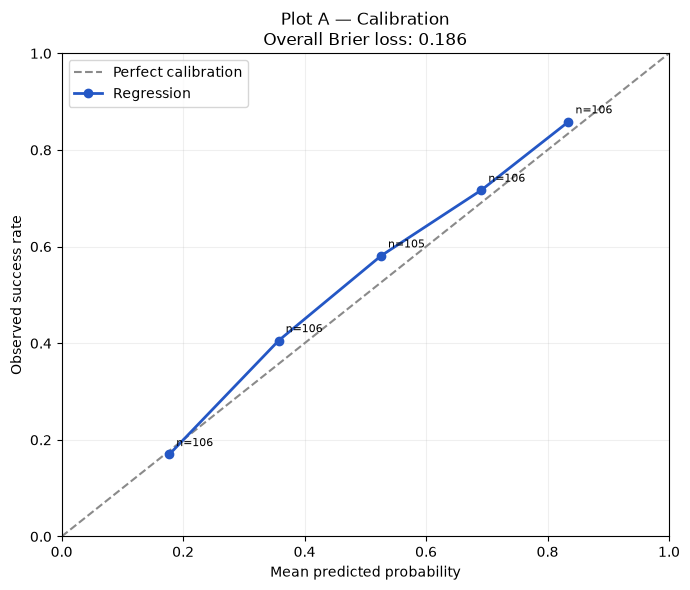

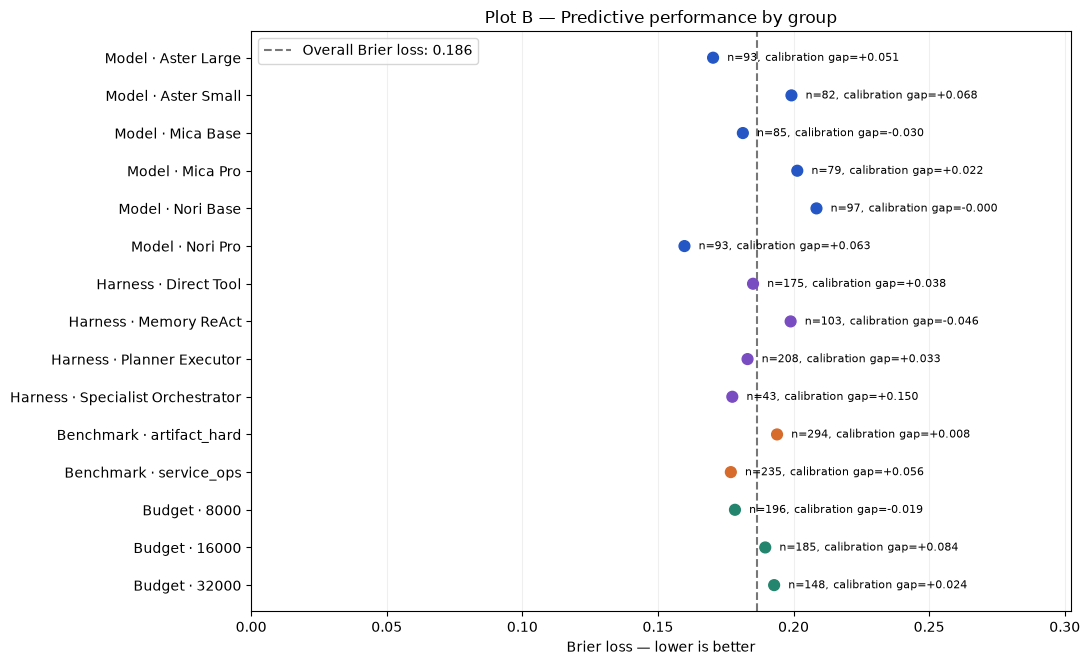

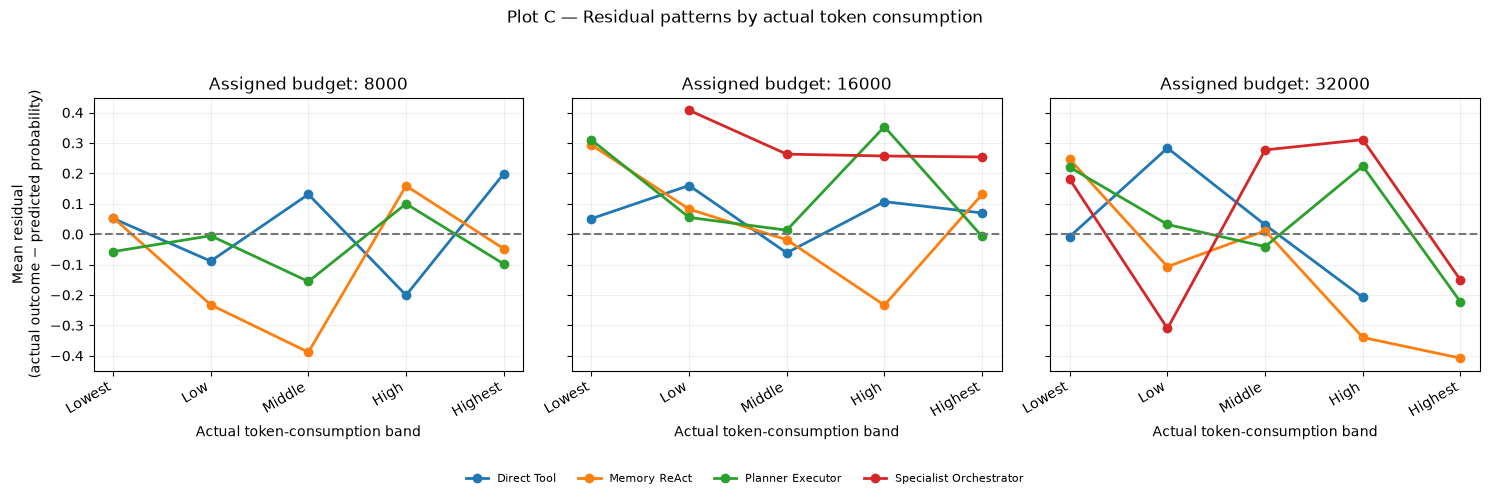

In [56]:
# DO NOT MODIFY
regression_output = fit_and_predict(
    train_runs=train_runs,
    train_tasks=train_tasks,
    evaluation_runs=evaluation_runs,
    evaluation_tasks=evaluation_tasks,
)

diagnostic_plots = plot_regression_diagnostics(
    regression_output=regression_output,
    evaluation_tasks_with_outcomes=evaluation_tasks_with_outcomes,
)


---

## Check your answers can be read

Optional, and it costs nothing. The cell below reads this notebook **from disk**
and reports how many answers it can find — so it catches both an answer cell that
got broken while editing and edits you have not saved yet. Save first, then run it.


In [57]:
# Optional: check that your answers can be read, before you submit.
#
# This reads SUBMISSION.ipynb FROM DISK, so it also tells you whether your most
# recent edits were actually saved. Save first (Cmd/Ctrl-S), then run this.
import json, re

_TAG = lambda c: (c.get("metadata") or {}).get("litmus", {}).get("answer")
_HEAD = re.compile(r"^[ \t]*\**[ \t]*Answer to Q(\d+)[ \t]*:?[ \t]*\**[ \t]*", re.MULTILINE)
_PLACEHOLDER = "_Write your response here"

nb = json.load(open("SUBMISSION.ipynb"))
answered, blank = set(), set()
for cell in nb["cells"]:
    text = "".join(cell.get("source") or [])
    n = _TAG(cell)
    if n is None:
        m = _HEAD.search(text) if cell.get("cell_type") == "markdown" else None
        n = int(m.group(1)) if m else None
    if n is None:
        continue
    body = _HEAD.sub("", text)
    body = "".join(l for l in body.splitlines(keepends=True)
                   if _PLACEHOLDER not in l).strip()
    (answered if body else blank).add(n)

# Q1-Q14 ONLY. The modelling question is answered in the `fit_and_predict`
# cell and ships with no answer cell of its own, so counting it here reported it
# NOT READABLE on every run and sent you looking for a cell that does not exist.
WRITTEN = range(1, 15)

missing = sorted(set(WRITTEN) - answered - blank)
print(f"answers found : {len(answered)}/{len(WRITTEN)}")
if blank:
    print(f"still blank   : {', '.join('Q%d' % n for n in sorted(blank))}")
if missing:
    print(f"NOT READABLE  : {', '.join('Q%d' % n for n in missing)}")
    print("                Those answer cells could not be located. Check you have not")
    print("                deleted the cell or its '**Answer to Qn**' heading.")

# The coding question separately: it is code, not prose, so "did you write
# something" is the wrong question. What matters is that the cell is still there
# and no longer raises NotImplementedError.
_CODING = [c for c in nb["cells"]
           if (c.get("metadata") or {}).get("litmus_id") == "q15_fit_and_predict"]
_src = "".join(_CODING[0].get("source") or []) if _CODING else ""
if not _CODING:
    print("Q15           : NOT READABLE - the `fit_and_predict` cell is not in the file.")
elif "NotImplementedError" in _src:
    print("Q15           : still the unmodified template (fit_and_predict not implemented).")
else:
    print("Q15           : implemented.")

if not missing and not blank:
    print(f"All {len(WRITTEN)} answer cells were found and contain text.")


answers found : 14/14
Q15           : implemented.
All 14 answer cells were found and contain text.


---

## Done

Save the notebook with outputs intact, then submit by running `litmus submit`.
